In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress, ttest_ind, fisher_exact, describe, mode
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score, r2_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid

In [2]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

1


In [3]:
#load npz file
basis_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
basis_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    basis_all_cycles.append(cycle_np_file['new_decomp_basis'])

basis_all_cycles = np.array(basis_all_cycles)

1


In [4]:
n_components, n_DHSs = mixture_all_cycles[0].shape

In [5]:
mixture_all_cycles.shape

(2, 16, 3591898)

In [6]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/max_DHS_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220322.npy'
DHS_max_signal_array = np.load(file)

In [5]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

#top 10%
DHS_metadata['ind'] = DHS_metadata.index
DHS_metadata_sortby_mean_signal = DHS_metadata.sort_values(['mean_signal'], ascending=False)
top_10_percent_DHSs = DHS_metadata_sortby_mean_signal.iloc[:int(np.round(n_DHSs/10))]
top_10_percent_DHSs_inds = np.array(top_10_percent_DHSs['ind'])
top_10_percent_DHSs_identifiers = np.array(top_10_percent_DHSs['identifier'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [6]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [7]:
#load npz file
added_recon_all_cycles = []
removed_recon_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 2):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_added_removed_recon_flatinds_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    added_recon_all_cycles.append(cycle_np_file['added_recon'])
    removed_recon_all_cycles.append(cycle_np_file['removed_recon'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [9]:
#The component number for the summary data corresponds to the NMF component
comp0 = pd.read_table('/home/ctrader/lightfm_data/comp1_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp0 mean'])
comp1 = pd.read_table('/home/ctrader/lightfm_data/comp2_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp1 mean'])
comp2 = pd.read_table('/home/ctrader/lightfm_data/comp3_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp2 mean'])
comp3 = pd.read_table('/home/ctrader/lightfm_data/comp4_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp3 mean'])
comp4 = pd.read_table('/home/ctrader/lightfm_data/comp5_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp4 mean'])
comp5 = pd.read_table('/home/ctrader/lightfm_data/comp6_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp5 mean'])
comp6 = pd.read_table('/home/ctrader/lightfm_data/comp7_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp6 mean'])
comp7 = pd.read_table('/home/ctrader/lightfm_data/comp8_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp7 mean'])
comp8 = pd.read_table('/home/ctrader/lightfm_data/comp9_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp8 mean'])
comp9 = pd.read_table('/home/ctrader/lightfm_data/comp10_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp9 mean'])
comp10 = pd.read_table('/home/ctrader/lightfm_data/comp11_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp10 mean'])
comp11 = pd.read_table('/home/ctrader/lightfm_data/comp12_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp11 mean'])
comp12 = pd.read_table('/home/ctrader/lightfm_data/comp13_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp12 mean'])
comp13 = pd.read_table('/home/ctrader/lightfm_data/comp14_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp13 mean'])
comp14 = pd.read_table('/home/ctrader/lightfm_data/comp15_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp14 mean'])
comp15 = pd.read_table('/home/ctrader/lightfm_data/comp16_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp15 mean'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (0) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [10]:
all_comps_average_signal = comp0[['name', 'comp0 mean']].merge(comp1[['name', 'comp1 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp2[['name', 'comp2 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp3[['name', 'comp3 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp4[['name', 'comp4 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp5[['name', 'comp5 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp6[['name', 'comp6 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp7[['name', 'comp7 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp8[['name', 'comp8 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp9[['name', 'comp9 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp10[['name', 'comp10 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp11[['name', 'comp11 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp12[['name', 'comp12 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp13[['name', 'comp13 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp14[['name', 'comp14 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp15[['name', 'comp15 mean']], how='inner', on='name')
all_comps_average_signal['average over all comps'] = all_comps_average_signal.mean(axis=1)
# all_comps_average_signal['average over all comps'] = (all_comps_average_signal['comp0 mean'] + all_comps_average_signal['comp1 mean'] + all_comps_average_signal['comp2 mean'] + all_comps_average_signal['comp3 mean'] + all_comps_average_signal['comp4 mean'] + all_comps_average_signal['comp5 mean'] + all_comps_average_signal['comp6 mean'] + all_comps_average_signal['comp7 mean'] + all_comps_average_signal['comp8 mean'] + all_comps_average_signal['comp9 mean'] + all_comps_average_signal['comp10 mean'] + all_comps_average_signal['comp11 mean'] + all_comps_average_signal['comp12 mean'] + all_comps_average_signal['comp13 mean'] + all_comps_average_signal['comp14 mean'] + all_comps_average_signal['comp15 mean'])/16
all_comps_average_signal['name'] = all_comps_average_signal['name'].astype(str)
all_comps_average_signal = all_comps_average_signal.set_index(['name'])
# old_columns = list(all_comps_average_signal.columns).extend(['max signal'])
# all_comps_average_signal.columns = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
all_comps_average_signal['max signal'] = all_comps_average_signal.idxmax(axis=1)
# all_comps_average_signal.columns = old_columns

DHS_metadata_identifiers = np.array(DHS_metadata['identifier'])

all_comps_average_signal = all_comps_average_signal.loc[DHS_metadata_identifiers]
top_10_percent_T_F = np.array([False]*len(all_comps_average_signal))
top_10_percent_T_F[top_10_percent_DHSs_inds] = True
all_comps_average_signal['top 10 percent'] = top_10_percent_T_F
all_comps_average_signal

/tmp/ipykernel_115500/4162047146.py:16: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  all_comps_average_signal['average over all comps'] = all_comps_average_signal.mean(axis=1)


,comp0 mean,comp1 mean,comp2 mean,comp3 mean,comp4 mean,comp5 mean,comp6 mean,comp7 mean,comp8 mean,comp9 mean,comp10 mean,comp11 mean,comp12 mean,comp13 mean,comp14 mean,comp15 mean,average over all comps,max signal,top 10 percent
name,,,,,,,,,,,,,,,,,,,
1.10011,0.053318,0.046712,0.039907,0.034054,0.029935,0.019642,0.050381,0.044771,0.038645,0.052703,0.028230,0.073723,0.043809,0.059390,0.188392,0.038370,0.052624,comp14 mean,False
1.10021,0.012199,0.006616,0.009675,0.005551,0.009631,0.015424,0.037962,0.003689,0.003913,0.006651,0.014848,0.009479,0.012386,0.008923,0.008113,0.004985,0.010628,comp6 mean,False
1.10025,0.013972,0.010649,0.002742,0.005082,0.004388,0.004117,0.010228,0.085321,0.003772,0.005397,0.006319,0.011102,0.003377,0.002977,0.005027,0.015383,0.011866,comp7 mean,False
1.10027,0.002374,0.003701,0.025612,0.018267,0.005331,0.021985,0.032393,0.008670,0.010130,0.010930,0.006678,0.003414,0.000000,0.005247,0.015185,0.002535,0.010778,comp6 mean,False
1.1003,0.017845,0.008636,0.009204,0.007383,0.013745,0.008851,0.032531,0.006222,0.006340,0.007592,0.031536,0.004111,0.014399,0.013492,0.006270,0.012739,0.012556,comp6 mean,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Y.994281,0.016663,0.013051,0.006976,0.008886,0.013321,0.019894,0.044953,0.010084,0.012202,0.006862,0.017083,0.012507,0.017318,0.012432,0.019537,0.017870,0.015602,comp6 mean,False
Y.994286,0.003373,0.007940,0.003355,0.002987,0.008398,0.005565,0.007886,0.005332,0.002115,0.004837,0.001810,0.005148,0.001989,0.004099,0.007139,0.003393,0.004710,comp4 mean,False
Y.994292,0.034594,0.021025,0.013023,0.017206,0.024326,0.086499,0.231924,0.011905,0.017295,0.018428,0.025081,0.018944,0.029714,0.030595,0.021135,0.143163,0.046554,comp6 mean,False


**increasing threshold vs number of removed DHSs**

In [5]:
#load npz file
mixture_1_cycle_multiple_thresh = []
to0_thresh_list = ['0.01', '0.001', '0.0001', '1e-05', '1e-06', '1e-07', '1e-08', '1e-09', '0.0']
to1_thresh_list = ['0.99', '0.999', '0.9999', '0.99999', '0.999999', '0.9999999', '0.99999999', '0.999999999', '1.0']

for i in range(len(to0_thresh_list)):
    print(i)
    to0_thresh = to0_thresh_list[i]
    to1_thresh = to1_thresh_list[i]
    if to0_thresh == '0.0':
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh'+to0_thresh+'_to1thresh'+to1_thresh+'_cycle1_CT20220323.npz'
    else:
        filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh'+to0_thresh+'_to1thresh'+to1_thresh+'_cycle1_CT20220329.npz'
    cycle_np_file = np.load(filename)
    mixture_1_cycle_multiple_thresh.append(cycle_np_file['new_decomp_mixture'])

mixture_1_cycle_multiple_thresh = np.array(mixture_1_cycle_multiple_thresh)

0
1
2
3
4
5
6
7
8


In [16]:
mixture_1_cycle_multiple_thresh_sum = np.sum(mixture_1_cycle_multiple_thresh, axis=1)

In [18]:
mixture_1_cycle_multiple_thresh_all_0s = np.where(mixture_1_cycle_multiple_thresh_sum==0)

In [33]:
number_of_removed_DHSs = []
for i in [0, 1, 2, 8]:
    number_of_removed_DHSs.append(len(mixture_1_cycle_multiple_thresh_all_0s[0][mixture_1_cycle_multiple_thresh_all_0s[0]==i]))
number_of_removed_DHSs = np.array(number_of_removed_DHSs)

Text(0.5, 1.0, 'Removed DHSs through 1 Cycle with Each Threshold Pair\nReconstruction Threshold Flip')

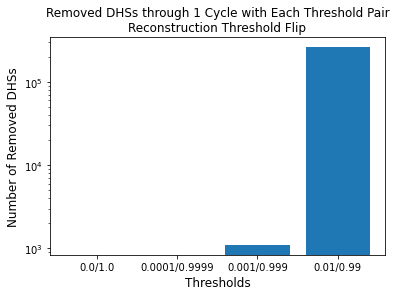

In [48]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.bar(np.flip(np.arange(len(number_of_removed_DHSs))), number_of_removed_DHSs)

threshold_vals = ['0.01/0.99', '0.001/0.999', '0.0001/0.9999', '0.0/1.0']
plt.xticks(np.flip(np.arange(len(number_of_removed_DHSs))), threshold_vals)

plt.yscale('log')

plt.xlabel('Thresholds', fontsize=12)
plt.ylabel('Number of Removed DHSs', fontsize=12)
plt.title('Removed DHSs through 1 Cycle with Each Threshold Pair\nReconstruction Threshold Flip')

**Removed Biosamples**

In [10]:
all_0_biosample_inds = np.where(np.sum(basis_all_cycles, axis=2)==0)

all_0_biosample_inds_cycle1 = all_0_biosample_inds[1][all_0_biosample_inds[0]==1]

In [12]:
#finding removed biosample_inds
removed_biosample_inds_all_cycles = []
for i in range(1):
    removed_biosample_inds_all_cycles.append(removed_flat_inds_all_cycles[i]  // n_DHSs)
    
#finding removed biosample_inds
added_biosample_inds_all_cycles = []
for i in range(1):
    added_biosample_inds_all_cycles.append(added_flat_inds_all_cycles[i]  // n_DHSs)

In [13]:
#finding the change in call numbers for all biosamples
biosamples = np.arange(733)
all_biosample_net_count = []
for b in biosamples:
    biosample_net_count = []
    biosample_net_count.append(biosample_df.loc[b]['DHSs in Index'])
    for i in range(1):
        removed = len(removed_biosample_inds_all_cycles[i][removed_biosample_inds_all_cycles[i]==b])
        added = len(added_biosample_inds_all_cycles[i][added_biosample_inds_all_cycles[i]==b])
        biosample_net_count.append(biosample_net_count[i]+added-removed)
    all_biosample_net_count.append(biosample_net_count)
all_biosample_net_count = np.array(all_biosample_net_count)

In [14]:
biosample_df.loc[all_0_biosample_inds_cycle1]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index


In [15]:
np.mean(np.array(biosample_df['DCC SPOT score']))

0.5001987721691677

**How does mean DHS signal change after DHSs are removed each cycle** 

In [16]:
not_0_dhs_inds = np.where(np.sum(mixture_all_cycles, axis=1)!=0)

not_0_dhs_inds_cycle1 = not_0_dhs_inds[1][not_0_dhs_inds[0]==1]

In [17]:
print(len(not_0_dhs_inds_cycle1))

3591898


In [18]:
print(np.mean(DHS_metadata['mean_signal']))
print(np.mean(DHS_metadata.loc[not_0_dhs_inds_cycle1]['mean_signal']))

0.6401371981706325
0.6401371981706325


**Top 10% DHSs for each Mixture**

In [19]:
#quantitatively comparing mixture embeddings
mixture_all_cycles_10per = mixture_all_cycles[:, :, top_10_percent_DHSs_inds]

**Top comp of basis and top 10% mixtures**

In [20]:
#top comps
mixture_all_cycles_10per_top_comp = np.argmax(mixture_all_cycles_10per, axis=1)
mixture_all_cycles_10per_top_comp_val = np.max(mixture_all_cycles_10per, axis=1)

#sum
mixture_all_cycles_10per_sum = np.sum(mixture_all_cycles_10per, axis=1)

In [21]:
mixture_all_cycles_10per_top_comp_notall0 = np.where(mixture_all_cycles_10per_sum==0, 
                                                     np.nan, 
                                                     mixture_all_cycles_10per_top_comp)

mixture_all_cycles_10per_top_comp_val_notall0 = np.where(mixture_all_cycles_10per_sum==0, 
                                                         np.nan, 
                                                         mixture_all_cycles_10per_top_comp_val)

mixture_all_cycles_10per[np.where(mixture_all_cycles_10per_sum==0)[0],
                         :, 
                         np.where(mixture_all_cycles_10per_sum==0)[1]]=np.nan

In [22]:
#top comps
basis_all_cycles_top_comp = np.argmax(basis_all_cycles, axis=2)
basis_all_cycles_top_comp_val = np.max(basis_all_cycles, axis=2)

#sum
basis_all_cycles_sum = np.sum(basis_all_cycles, axis=2)

In [23]:
basis_all_cycles_top_comp_notall0 = np.where(basis_all_cycles_sum==0, 
                                             np.nan, 
                                             basis_all_cycles_top_comp)

basis_all_cycles_top_comp_val_notall0 = np.where(basis_all_cycles_sum==0, 
                                                 np.nan, 
                                                 basis_all_cycles_top_comp_val)

basis_all_cycles[np.where(basis_all_cycles_sum==0)[0],
                 np.where(basis_all_cycles_sum==0)[1],
                 :]=np.nan

**Mixture (top 10%) and Basis Purity**

In [24]:
#top 10% DHSs
mixture_all_cycles_10per_top_comp_val = np.nanmax(mixture_all_cycles_10per, axis=1)
mixture_all_cycles_10per_nansum = np.nansum(mixture_all_cycles_10per, axis=1)

mixture_all_cycles_10per_pur_by_sum = mixture_all_cycles_10per_top_comp_val / mixture_all_cycles_10per_nansum

In [25]:
basis_all_cycles_top_comp_val = np.nanmax(basis_all_cycles, axis=2)
basis_all_cycles_nansum = np.nansum(basis_all_cycles, axis=2)

basis_all_cycles_pur_by_sum = basis_all_cycles_top_comp_val / basis_all_cycles_nansum

Text(0.5, 1.07, 'NMF Loading Purity (by Top Component Value/Sum of Components)\nReconstruction Threshold Flip, Threshold=0.0/1.0')

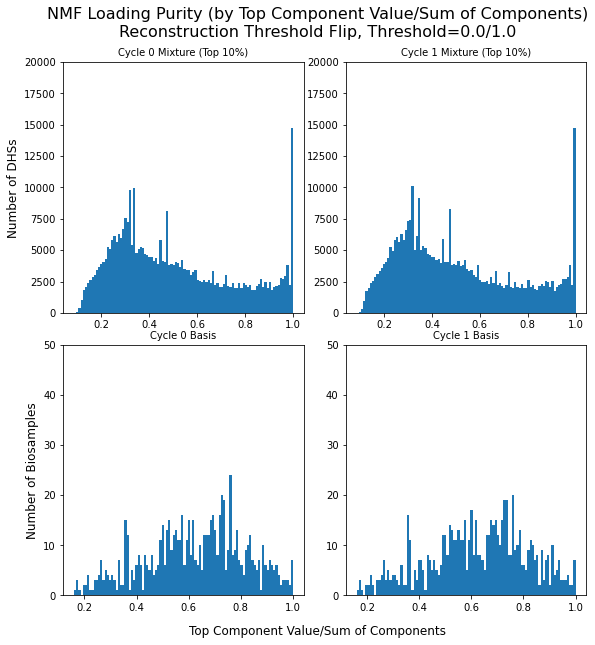

In [26]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ind in range(2):
    axes[ind].hist(mixture_all_cycles_10per_pur_by_sum[ind], bins=100)
    axes[ind+2].hist(basis_all_cycles_pur_by_sum[ind], bins=100)
    axes[ind].set_ylim([0, 20000])#70000
    axes[ind+2].set_ylim([0, 50])#500
    axes[ind].set_title('Cycle '+str(ind)+' Mixture (Top 10%)', fontsize=10)
    axes[ind+2].set_title('Cycle %s Basis' %(ind), fontsize=10)

axes[0].set_ylabel('Number of DHSs', fontsize=12)
axes[2].set_ylabel('Number of Biosamples', fontsize=12)
fig.text(0.5, -0.02, 'Top Component Value/Sum of Components', ha='center', fontsize=12)
plt.suptitle('NMF Loading Purity (by Top Component Value/Sum of Components)\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1.07)

In [27]:
#finding the number of comps it takes to make up 50% of loading sum
threshold = 0.5
basis_purity_count_all_cycles = []
for cycle in range(2):
    count_per_cycle = []
    for biosample in range(len(basis_all_cycles[0, :, 0])):
        loading_sum = basis_all_cycles_nansum[cycle, biosample]
        loading = basis_all_cycles[cycle, biosample, :]
        loading_sorted = -np.sort(-loading)
        count = 0
        running_sum = 0
        while running_sum < (threshold * loading_sum):
            running_sum += loading_sorted[count]
            count += 1
        count_per_cycle.append(count)
    basis_purity_count_all_cycles.append(count_per_cycle)
basis_purity_count_all_cycles = np.array(basis_purity_count_all_cycles)

In [28]:
#finding the number of comps it takes to make up 50% of loading sum
threshold = 0.5
mixture_purity_count_all_cycles_10per = []
for cycle in range(2):
    count_per_cycle = []
    for dhs in range(len(mixture_all_cycles_10per[0, 0, :])):
        loading_sum = mixture_all_cycles_10per_nansum[cycle, dhs]
        loading = mixture_all_cycles_10per[cycle, :, dhs]
        loading_sorted = -np.sort(-loading)
        count = 0
        running_sum = 0
        while running_sum < (threshold * loading_sum):
            running_sum += loading_sorted[count]
            count += 1
        count_per_cycle.append(count)
    mixture_purity_count_all_cycles_10per.append(count_per_cycle)
mixture_purity_count_all_cycles_10per = np.array(mixture_purity_count_all_cycles_10per)

Text(0.5, 1.07, 'NMF Loading Purity (by Number of Components Making Up 50% of Loading Sum)\nReconstruction Threshold Flip, Threshold=0.0/1.0')

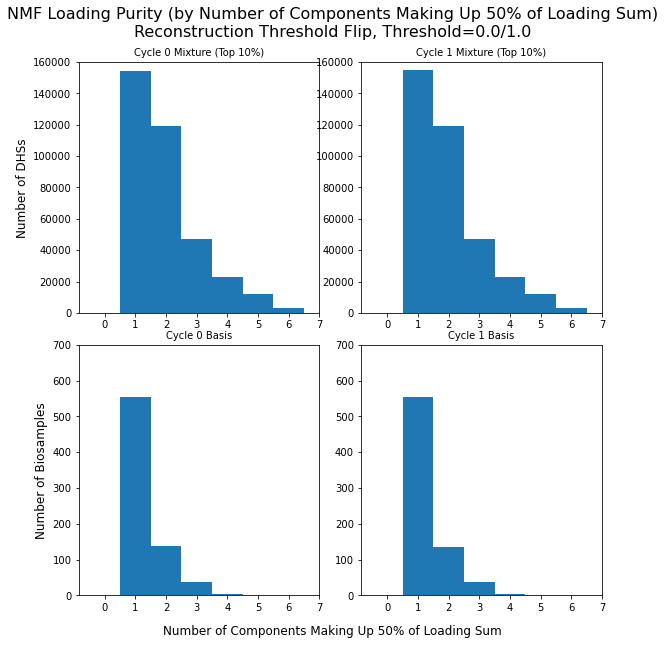

In [29]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ind in range(2):
    axes[ind].hist(mixture_purity_count_all_cycles_10per[ind], width=1, align='left', bins=[0, 1, 2, 3, 4, 5, 6, 7])
    axes[ind+2].hist(basis_purity_count_all_cycles[ind], width=1, align='left', bins=[0, 1, 2, 3, 4, 5, 6, 7])
    axes[ind].set_ylim([0, 160000])#70000
    axes[ind+2].set_ylim([0, 700])#500
    axes[ind].set_title('Cycle '+str(ind)+' Mixture (Top 10%)', fontsize=10)
    axes[ind+2].set_title('Cycle %s Basis' %(ind), fontsize=10)
    axes[ind].set_xticks([0, 1, 2, 3, 4, 5, 6, 7])
    axes[ind+2].set_xticks([0, 1, 2, 3, 4, 5, 6, 7])
#     axes[ind].set_xlim([0, 7])
#     axes[ind+4].set_xlim([0, 7])

axes[0].set_ylabel('Number of DHSs', fontsize=12)
axes[2].set_ylabel('Number of Biosamples', fontsize=12)
fig.text(0.5, -0.02, 'Number of Components Making Up 50% of Loading Sum', ha='center', fontsize=12)
plt.suptitle('NMF Loading Purity (by Number of Components Making Up 50% of Loading Sum)\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1.07)

**Heatmaps (of just DHSs that change component)**

In [30]:
heatmap_mixture_all_cycles_10per_top_comp_comparison = np.zeros((1, 16,16), dtype=int)

changed_dhss_all_cycles = []
changed_dhss_original_comp = []
changed_dhss_new_comp = []
changed_dhss_original_comp_val = []
changed_dhss_new_comp_val = []

for i in range(1):
    changed_dhss_1_cycle = []
    original_comp = []
    new_comp = []
    original_comp_val = []
    new_comp_val = []
    
    for comp1, comp0, dhs, val1, val0 in zip(mixture_all_cycles_10per_top_comp_notall0[i+1], 
                                             mixture_all_cycles_10per_top_comp_notall0[i], 
                                             range(len(mixture_all_cycles_10per_top_comp_notall0[0])),
                                             mixture_all_cycles_10per_top_comp_val_notall0[i+1], 
                                             mixture_all_cycles_10per_top_comp_val_notall0[i],):
        if ((comp1!=comp0) and (~np.isnan(comp0)) and (~np.isnan(comp1))):
            comp0 = comp0.astype(int)
            comp1 = comp1.astype(int)
            heatmap_mixture_all_cycles_10per_top_comp_comparison[i, comp1, comp0] += 1
            changed_dhss_1_cycle.append(dhs)
            original_comp.append(comp0)
            new_comp.append(comp1)
            original_comp_val.append(val0)
            new_comp_val.append(val1)
            
    changed_dhss_all_cycles.append(np.array(changed_dhss_1_cycle))
    changed_dhss_original_comp.append(np.array(original_comp))
    changed_dhss_new_comp.append(np.array(new_comp))
    changed_dhss_original_comp_val.append(np.array(original_comp_val))
    changed_dhss_new_comp_val.append(np.array(new_comp_val))

changed_all_dhss_all_cycles = []
for i in changed_dhss_all_cycles:
    changed_all_dhss_all_cycles.append(top_10_percent_DHSs_inds[i])

In [31]:
changed_all_dhss_all_cycles_arr = []
for i in changed_all_dhss_all_cycles:
    changed_all_dhss_all_cycles_arr.extend(i)
changed_all_dhss_all_cycles_arr = np.array(changed_all_dhss_all_cycles_arr)
    
changed_dhss_original_comp_arr = []
for i in changed_dhss_original_comp:
    changed_dhss_original_comp_arr.extend(i)
changed_dhss_original_comp_arr = np.array(changed_dhss_original_comp_arr)
    
changed_dhss_new_comp_arr = []
for i in changed_dhss_new_comp:
    changed_dhss_new_comp_arr.extend(i)
changed_dhss_new_comp_arr = np.array(changed_dhss_new_comp_arr)
    
changed_dhss_original_comp_val_arr = []
for i in changed_dhss_original_comp_val:
    changed_dhss_original_comp_val_arr.extend(i)
changed_dhss_original_comp_val_arr = np.array(changed_dhss_original_comp_val_arr)
    
changed_dhss_new_comp_val_arr = []
for i in changed_dhss_new_comp_val:
    changed_dhss_new_comp_val_arr.extend(i)
changed_dhss_new_comp_val_arr = np.array(changed_dhss_new_comp_val_arr)

In [32]:
heatmap_mixture_all_cycles_10per_top_comp_comparison_sum = np.sum(heatmap_mixture_all_cycles_10per_top_comp_comparison, axis=0)

In [33]:
np.sum(heatmap_mixture_all_cycles_10per_top_comp_comparison_sum)

1279

Text(0.5, 1.0, 'Comparing Changed DHS Top Components of Previous and New NMF Mixtures Summed Across All Cycles\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs')

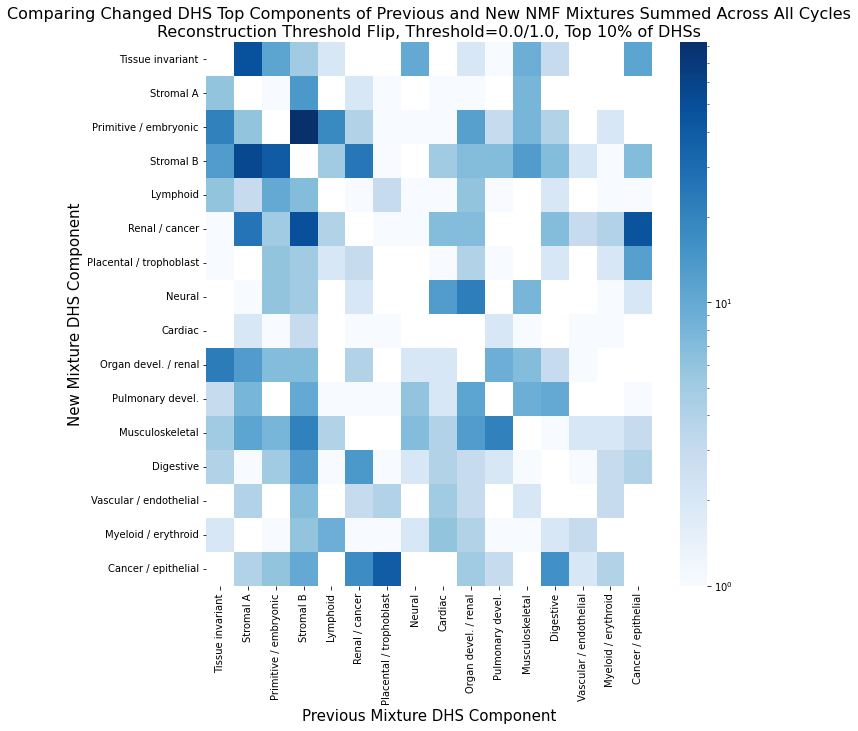

In [34]:
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')
ax = sns.heatmap(heatmap_mixture_all_cycles_10per_top_comp_comparison_sum, cmap='Blues', cbar=True, xticklabels=comps_for_heatmap, yticklabels=comps_for_heatmap, norm=LogNorm()) # 
ax.set_ylabel('New Mixture DHS Component', fontsize=15)
ax.set_xlabel('Previous Mixture DHS Component', fontsize=15)
ax.set_title('Comparing Changed DHS Top Components of Previous and New NMF Mixtures Summed Across All Cycles\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs', fontsize=16)

In [35]:
heatmap_basis_all_cycles_top_comp_comparison = np.zeros((1, 16,16), dtype=int)

changed_biosamples_all_cycles = []
changed_biosamples_original_comp = []
changed_biosamples_new_comp = []
changed_biosamples_original_comp_val = []
changed_biosamples_new_comp_val = []

for i in range(1):
    changed_biosamples_1_cycle = []
    original_comp = []
    new_comp = []
    original_comp_val = []
    new_comp_val = []
    
    for comp1, comp0, biosample, val1, val0 in zip(basis_all_cycles_top_comp_notall0[i+1], 
                                             basis_all_cycles_top_comp_notall0[i], 
                                             range(len(basis_all_cycles_top_comp_notall0[0])),
                                             basis_all_cycles_top_comp_val_notall0[i+1], 
                                             basis_all_cycles_top_comp_val_notall0[i],):
        if ((comp1!=comp0) and (~np.isnan(comp0)) and (~np.isnan(comp1))):
#             print(biosample)
            comp0 = comp0.astype(int)
            comp1 = comp1.astype(int)
#             print(comp0, comp1, val0, val1)
            heatmap_basis_all_cycles_top_comp_comparison[i, comp1, comp0] += 1
            changed_biosamples_1_cycle.append(biosample)
            original_comp.append(comp0)
            new_comp.append(comp1)
            original_comp_val.append(val0)
            new_comp_val.append(val1)
            
    changed_biosamples_all_cycles.append(np.array(changed_biosamples_1_cycle))
    changed_biosamples_original_comp.append(np.array(original_comp))
    changed_biosamples_new_comp.append(np.array(new_comp))
    changed_biosamples_original_comp_val.append(np.array(original_comp_val))
    changed_biosamples_new_comp_val.append(np.array(new_comp_val))

In [36]:
changed_biosamples_all_cycles_arr = []
for i in changed_biosamples_all_cycles:
    changed_biosamples_all_cycles_arr.extend(i)
changed_biosamples_all_cycles_arr = np.array(changed_biosamples_all_cycles_arr)
    
changed_biosamples_original_comp_arr = []
for i in changed_biosamples_original_comp:
    changed_biosamples_original_comp_arr.extend(i)
changed_biosamples_original_comp_arr = np.array(changed_biosamples_original_comp_arr)
    
changed_biosamples_new_comp_arr = []
for i in changed_biosamples_new_comp:
    changed_biosamples_new_comp_arr.extend(i)
changed_biosamples_new_comp_arr = np.array(changed_biosamples_new_comp_arr)
    
changed_biosamples_original_comp_val_arr = []
for i in changed_biosamples_original_comp_val:
    changed_biosamples_original_comp_val_arr.extend(i)
changed_biosamples_original_comp_val_arr = np.array(changed_biosamples_original_comp_val_arr)
    
changed_biosamples_new_comp_val_arr = []
for i in changed_biosamples_new_comp_val:
    changed_biosamples_new_comp_val_arr.extend(i)
changed_biosamples_new_comp_val_arr = np.array(changed_biosamples_new_comp_val_arr)

In [37]:
heatmap_basis_all_cycles_top_comp_comparison_sum = np.sum(heatmap_basis_all_cycles_top_comp_comparison, axis=0)

In [38]:
np.sum(heatmap_basis_all_cycles_top_comp_comparison_sum)

5

Text(0.5, 1.0, 'Comparing Changed DHS Top Components of Previous and New NMF Basis Summed Across All Cycles\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs')

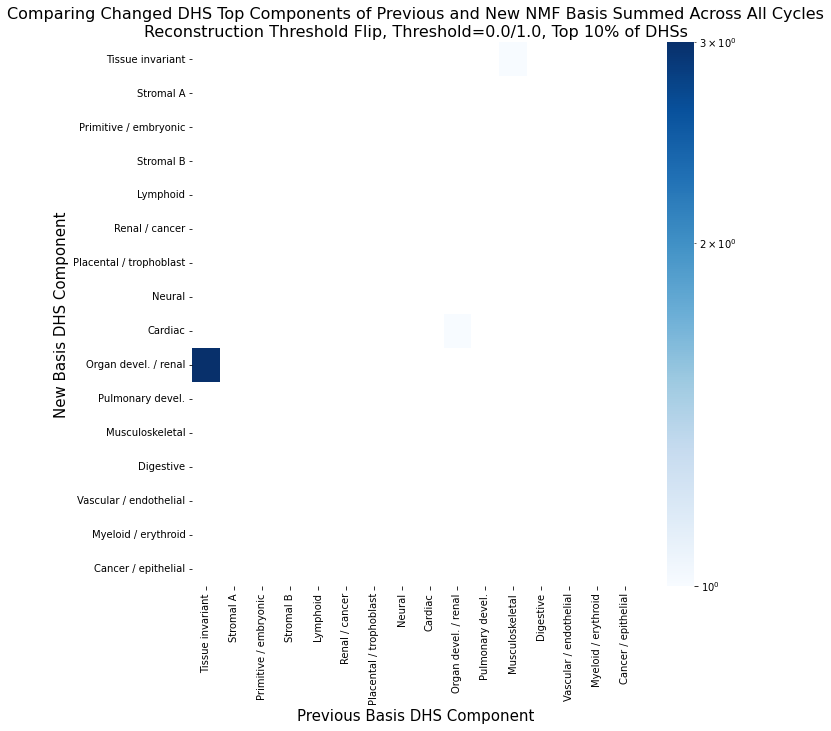

In [39]:
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')
ax = sns.heatmap(heatmap_basis_all_cycles_top_comp_comparison_sum, cmap='Blues', cbar=True, xticklabels=comps_for_heatmap, yticklabels=comps_for_heatmap, norm=LogNorm()) # 
ax.set_ylabel('New Basis DHS Component', fontsize=15)
ax.set_xlabel('Previous Basis DHS Component', fontsize=15)
ax.set_title('Comparing Changed DHS Top Components of Previous and New NMF Basis Summed Across All Cycles\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs', fontsize=16)

**Top 15 Biosamples of each component**

In [40]:
changed__biosamples_all_cycles = []
changed__biosamples_original_comp_all_cycles = []
changed__biosamples_new_comp_all_cycles = []
for i in range(1):
    print(i)
    changed__biosamples_1_cycle = []
    changed__biosamples_original_comp_1_cycle = []
    changed__biosamples_new_comp_1_cycle = []
    for changed_biosample, old_comp, new_comp in zip(changed_biosamples_all_cycles[i], 
                                                     changed_biosamples_original_comp[i], 
                                                     changed_biosamples_new_comp[i]):
        
        
        print(str(changed_biosample) + ',', 
              biosample_df.loc[changed_biosample]['Biosample name'] + ',', 
              comps_for_heatmap[old_comp] + ' ->', 
              comps_for_heatmap[new_comp] + ',',
              'SPOT = ' + str(biosample_df.loc[changed_biosample]['DCC SPOT score']))
        changed__biosamples_1_cycle.append(changed_biosample)
        changed__biosamples_original_comp_1_cycle.append(old_comp)
        changed__biosamples_new_comp_1_cycle.append(new_comp)
            
    changed__biosamples_all_cycles.append(np.array(changed__biosamples_1_cycle))
    changed__biosamples_original_comp_all_cycles.append(np.array(changed__biosamples_original_comp_1_cycle))
    changed__biosamples_new_comp_all_cycles.append(np.array(changed__biosamples_new_comp_1_cycle))

0
411, fKidney_renal_cortex_R, Tissue invariant -> Organ devel. / renal, SPOT = 0.5307
486, fKidney_R, Tissue invariant -> Organ devel. / renal, SPOT = 0.5321
531, fKidney, Tissue invariant -> Organ devel. / renal, SPOT = 0.438
719, fBone_arm_left, Musculoskeletal -> Tissue invariant, SPOT = 0.4059
728, fUmbilical_cord, Organ devel. / renal -> Cardiac, SPOT = 0.5652


In [41]:
top_15_biosample_inds = np.array(biosample_df[~biosample_df['Vocabulary representative'].isnull()].index)

In [42]:
changed_top15biosamples_all_cycles = []
changed_top15biosamples_original_comp_all_cycles = []
changed_top15biosamples_new_comp_all_cycles = []
for i in range(1):
    print(i)
    changed_top15biosamples_1_cycle = []
    changed_top15biosamples_original_comp_1_cycle = []
    changed_top15biosamples_new_comp_1_cycle = []
    for changed_biosample, old_comp, new_comp in zip(changed_biosamples_all_cycles[i], 
                                                     changed_biosamples_original_comp[i], 
                                                     changed_biosamples_new_comp[i]):
        
        if changed_biosample in top_15_biosample_inds:
            print(changed_biosample, biosample_df.loc[changed_biosample]['Biosample name'], comps_for_heatmap[old_comp], comps_for_heatmap[new_comp])
            changed_top15biosamples_1_cycle.append(changed_biosample)
            changed_top15biosamples_original_comp_1_cycle.append(old_comp)
            changed_top15biosamples_new_comp_1_cycle.append(new_comp)
            
    changed_top15biosamples_all_cycles.append(np.array(changed_top15biosamples_1_cycle))
    changed_top15biosamples_original_comp_all_cycles.append(np.array(changed_top15biosamples_original_comp_1_cycle))
    changed_top15biosamples_new_comp_all_cycles.append(np.array(changed_top15biosamples_new_comp_1_cycle))

0
486 fKidney_R Tissue invariant Organ devel. / renal
531 fKidney Tissue invariant Organ devel. / renal


In [43]:
biosample_df.loc[changed_top15biosamples_all_cycles[0]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
486,487,fKidney_R,Tissue invariant,ENCSR017TFH,ENCLB521YRN,ENCBS278PUM,AG8854,LN4936,DS20951,NaN,...,minElute,60.0,19.6,7830000.0,A+Sucrose,2011-11-15,25040896,0.5321,46710,46484
531,532,fKidney,Tissue invariant,ENCSR645GJD,ENCLB963LDG,ENCBS382CRI,AG8810,LN10157,DS20988,DS20987,...,Sucrose,70.0,32.98,18120000.0,A+Sucrose,2011-11-18,36520939,0.4380,52222,51894


**DHSs that change component**

In [18]:
convex_hull_outliers = []
f = open("/home/ajoshi/similarity_metrics/results/convex_hull_PC_vertices", "r")
for line in f:
    convex_hull_outliers.append(int(line.strip('\n')))
convex_hull_outliers = np.array(convex_hull_outliers)

In [69]:
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

In [17]:
mixture_all_cycles_top_comp = np.argmax(mixture_all_cycles, axis=1)

In [7]:
DHS_metadata[DHS_metadata['identifier']=='11.135271']

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component,ind
496476,chr11,5280660,5280871,11.135271,7.430968,451,5280770,5280730.0,5280790.0,Stromal A,496476


In [23]:
count=0
for outlier in convex_hull_outliers:
    if outlier in DHSs_changing_component:
        count+=1

In [24]:
count

0

In [9]:
original_comps = []
new_comps = []
DHSs_changing_component = []
unchanged_DHSs = []
for comp1, comp0, dhs in zip(mixture_all_cycles_top_comp[1], 
                             mixture_all_cycles_top_comp[0],
                             range(len(mixture_all_cycles_top_comp[0]))):
    if (comp1!=comp0):
        original_comps.append(comp0.astype(int))
        new_comps.append(comp1.astype(int))
        DHSs_changing_component.append(dhs)
    else:
        unchanged_DHSs.append(dhs)
        
original_comps = np.array(original_comps)
new_comps = np.array(new_comps)
DHSs_changing_component = np.array(DHSs_changing_component)
unchanged_DHSs = np.array(unchanged_DHSs)

In [10]:
DHSs_changing_component_identifiers = np.array(DHS_metadata.loc[DHSs_changing_component]['identifier'])

In [37]:
original_comps_mean_signals = []
new_comps_mean_signals = []
for identifier, original_comp, new_comp in zip(DHSs_changing_component_identifiers,
                                              original_comps, new_comps):
    dhs_mean_signals = all_comps_average_signal.loc[identifier]
    original_comps_mean_signals.append(dhs_mean_signals['comp' + str(original_comp) + ' mean'])
    new_comps_mean_signals.append(dhs_mean_signals['comp' + str(new_comp) + ' mean'])
    
original_comps_mean_signals = np.array(original_comps_mean_signals)
new_comps_mean_signals = np.array(new_comps_mean_signals)

In [14]:
added_dhss_average_over_all_comps = []
added_dhss_comp_specific_mean_signal = []
for i in range(16):
    local_inds_added_to_comp = np.where(new_comps==i)[0]
    DHSs = DHSs_changing_component_identifiers[local_inds_added_to_comp]
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    added_dhss_average_over_all_comps.append(np.array(DHS_signal_values_df['average over all comps']))
    added_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))

Text(0.5, 1.03, 'Mean Signal Values of DHSs Added to Each Component\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs')

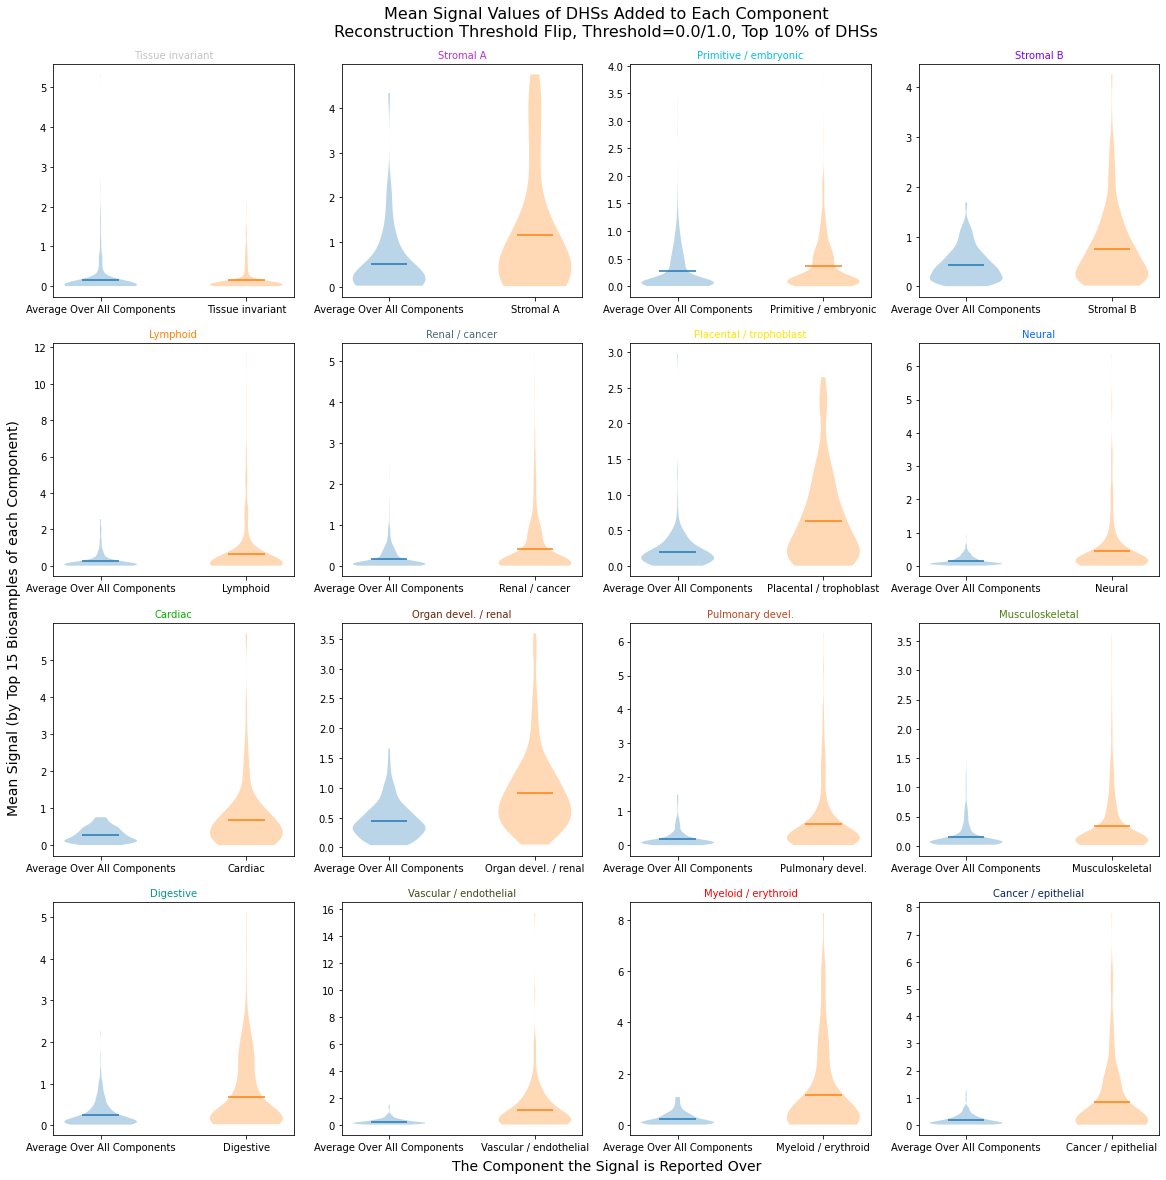

In [17]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.2)
fig.patch.set_facecolor('white')

violin_colors = ['#1f77b4', '#ff7f0e']
handles = list(plt.Rectangle((0,0),1,1, color=c, alpha=0.5) for c in violin_colors)

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    ax.violinplot(added_dhss_average_over_all_comps[ind], positions=[0], showextrema=False, showmeans=True)
    ax.violinplot(added_dhss_comp_specific_mean_signal[ind], positions=[1], showextrema=False, showmeans=True)
#     ax.set_ylim([0, 10])
    ax.set_title(comps_for_heatmap[ind], fontsize=10, color=color[ind])
#     ax.legend(handles, ['Average Over All Components', nmf_comps[ind]])
#     ax.legend(['All Components Averaged', 'All Components Mean', nmf_comps[ind], nmf_comps[ind]+' Mean'])
#     ax.set_xticks([])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Average Over All Components', comps_for_heatmap[ind]])




fig.text(0.5, 0.02, 'The Component the Signal is Reported Over', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Mean Signal (by Top 15 Biosamples of each Component)', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Signal Values of DHSs Added to Each Component\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs', fontsize=16, x=0.5, y=1.03)

In [18]:
original_dhss_average_over_all_comps = []
original_dhss_comp_specific_mean_signal = []
for i in range(16):
    local_inds_original_to_comp = np.where(original_comps==i)[0]
    DHSs = DHSs_changing_component_identifiers[local_inds_original_to_comp]
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    original_dhss_average_over_all_comps.append(np.array(DHS_signal_values_df['average over all comps']))
    original_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))

Text(0.5, 1.03, 'Mean Signal Values of DHSs Removed from Each Component\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs')

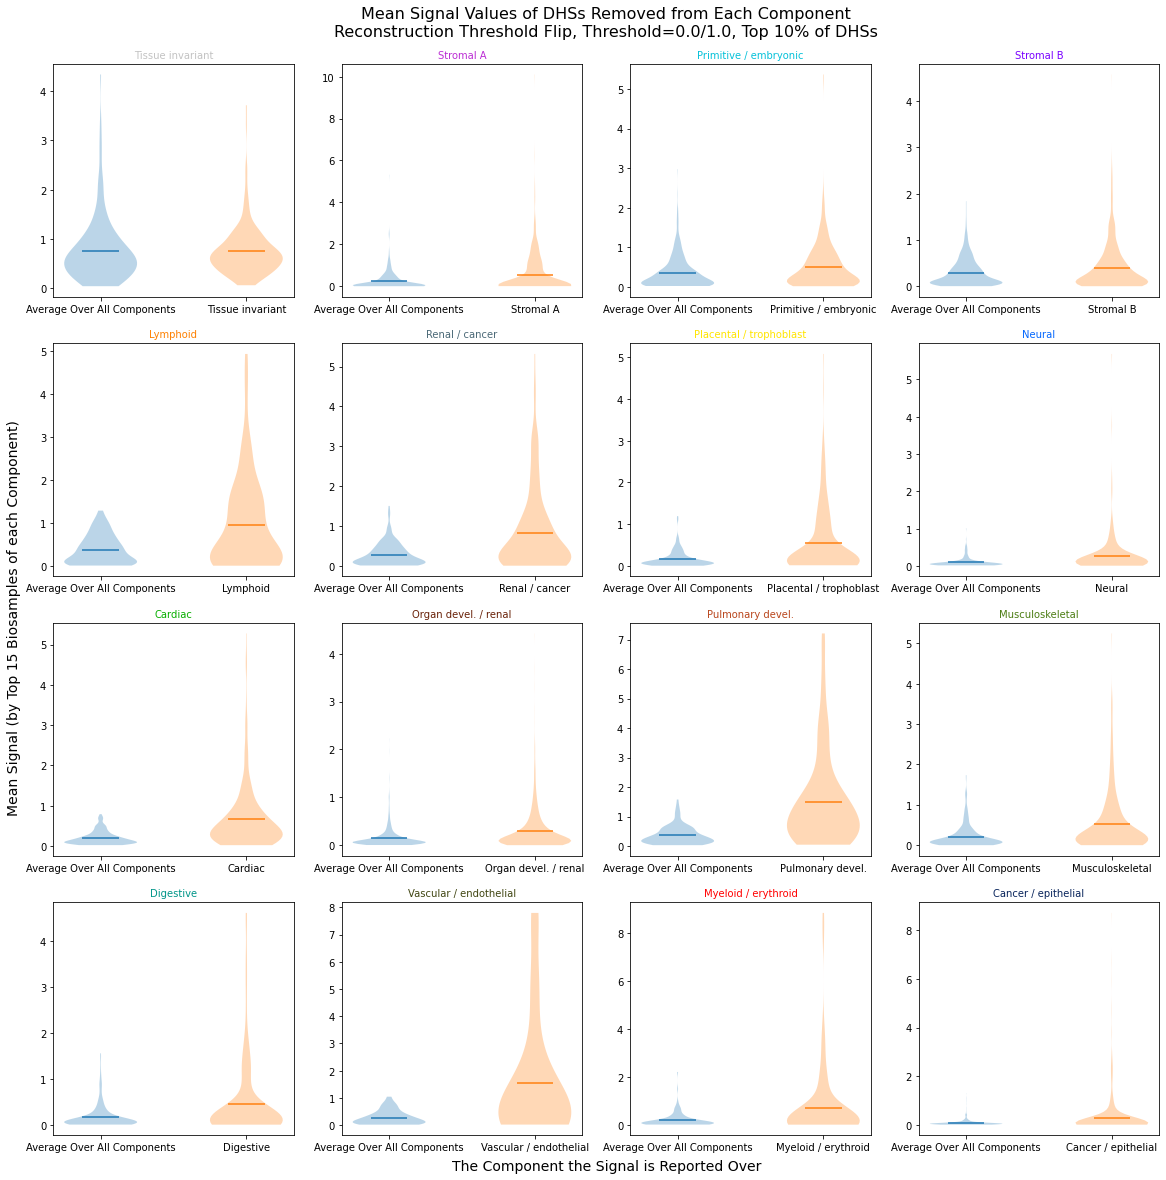

In [20]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.2)
fig.patch.set_facecolor('white')

violin_colors = ['#1f77b4', '#ff7f0e']
handles = list(plt.Rectangle((0,0),1,1, color=c, alpha=0.5) for c in violin_colors)

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    ax.violinplot(original_dhss_average_over_all_comps[ind], positions=[0], showextrema=False, showmeans=True)
    ax.violinplot(original_dhss_comp_specific_mean_signal[ind], positions=[1], showextrema=False, showmeans=True)
#     ax.set_ylim([0, 10])
    ax.set_title(comps_for_heatmap[ind], fontsize=10, color=color[ind])
#     ax.legend(handles, ['Average Over All Components', nmf_comps[ind]])
#     ax.legend(['All Components Averaged', 'All Components Mean', nmf_comps[ind], nmf_comps[ind]+' Mean'])
#     ax.set_xticks([])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Average Over All Components', comps_for_heatmap[ind]])




fig.text(0.5, 0.02, 'The Component the Signal is Reported Over', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Mean Signal (by Top 15 Biosamples of each Component)', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Signal Values of DHSs Removed from Each Component\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs', fontsize=16, x=0.5, y=1.03)

In [14]:
added_dhss_comp_specific_mean_signal = []
for i in range(16):
    local_inds_added_to_comp = np.where(new_comps==i)[0]
    DHSs = DHSs_changing_component_identifiers[local_inds_added_to_comp]
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    added_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))
    
original_dhss_comp_specific_mean_signal = []
for i in range(16):
    local_inds_original_to_comp = np.where(original_comps==i)[0]
    DHSs = DHSs_changing_component_identifiers[local_inds_original_to_comp]
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    original_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))

Text(0.5, 1.03, 'Mean Signal Values of Reassigned DHSs of Each Component\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs')

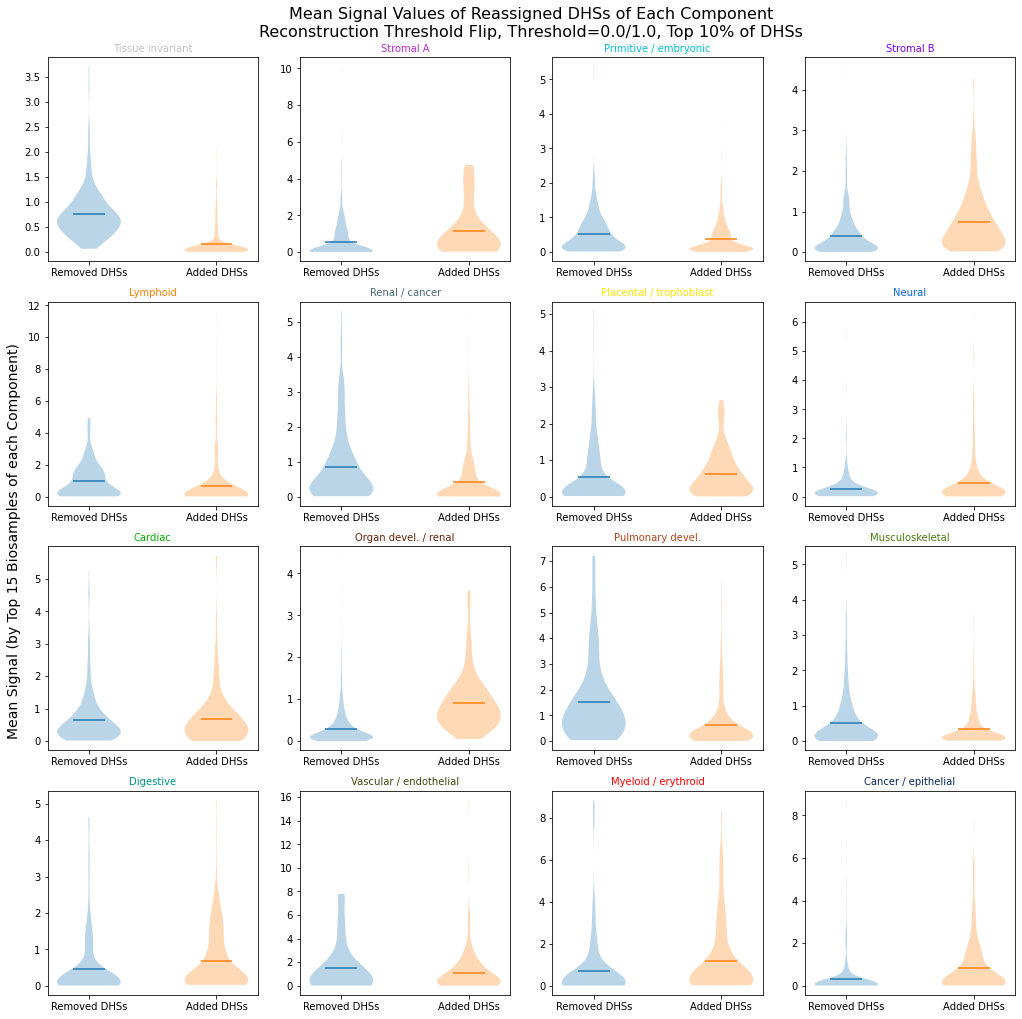

In [30]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(14,14))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.2)
fig.patch.set_facecolor('white')

violin_colors = ['#1f77b4', '#ff7f0e']
handles = list(plt.Rectangle((0,0),1,1, color=c, alpha=0.5) for c in violin_colors)

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    ax.violinplot(original_dhss_comp_specific_mean_signal[ind], positions=[0], showextrema=False, showmeans=True)
    ax.violinplot(added_dhss_comp_specific_mean_signal[ind], positions=[1], showextrema=False, showmeans=True)
    ax.set_title(comps_for_heatmap[ind], fontsize=10, color=color[ind])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Removed DHSs', 'Added DHSs'])

# fig.text(0.5, 0.02, 'The Component the Signal is Reported Over', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Mean Signal (by Top 15 Biosamples of each Component)', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Signal Values of Reassigned DHSs of Each Component\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs', fontsize=16, x=0.5, y=1.03)

In [62]:
mixture_all_cycles_top_comp = np.argmax(mixture_all_cycles, axis=1)

In [12]:
heatmap_mixture_all_cycles_top_comp_comparison = np.zeros((1, 16,16), dtype=int)
# heatmap_mixture_all_cycles_top_comp_random = np.zeros((1, 16,16), dtype=int)

changed_dhss_all_cycles = []
changed_dhss_original_comp = []
changed_dhss_new_comp = []
changed_dhss_numflips = []


for i in range(1):
    changed_dhss_1_cycle = []
    original_comp = []
    new_comp = []
    num_flips = []
    
    for comp1, comp0, dhs in zip(mixture_all_cycles_top_comp[i+1], 
                                 mixture_all_cycles_top_comp[i], 
                                 range(len(mixture_all_cycles_top_comp[0]))):
        if ((comp1!=comp0) and (~np.isnan(comp0)) and (~np.isnan(comp1))):
            comp0 = comp0.astype(int)
            comp1 = comp1.astype(int)
            heatmap_mixture_all_cycles_top_comp_comparison[i, comp1, comp0] += 1
#             rand_comp = random.randrange(16)
#             while rand_comp == comp0:
#                 rand_comp = random.randrange(16)
#             heatmap_mixture_all_cycles_top_comp_random[i, rand_comp, comp0] += 1
            changed_dhss_1_cycle.append(dhs)
            original_comp.append(comp0)
            new_comp.append(comp1)
            num_flips.append(len(np.where(removed_DHS_inds==dhs)[0]) + 
                             len(np.where(added_DHS_inds==dhs)[0]))
            
    changed_dhss_all_cycles.append(np.array(changed_dhss_1_cycle))
    changed_dhss_original_comp.append(np.array(original_comp))
    changed_dhss_new_comp.append(np.array(new_comp))
    changed_dhss_numflips.append(np.array(num_flips))

In [13]:
# #using mean signal of top 15 biosamples of each component
# original_comp_total_signal = np.array([])
# new_comp_total_signal = np.array([])
# for original_comp in range(16):
#     for new_comp in range(16):
#         changed_dhss = changed_dhss_all_cycles[0][((changed_dhss_original_comp[0]==original_comp) & 
#                                                    (changed_dhss_new_comp[0]==new_comp))]
#         if len(changed_dhss)>0:
#             changed_dhss_identifiers = DHS_metadata.loc[changed_dhss]['identifier']
#             signal_df = all_comps_average_signal.loc[changed_dhss_identifiers]
#             original_comp_signal = np.array(signal_df['comp'+str(original_comp)+' mean'])
#             new_comp_signal = np.array(signal_df['comp'+str(new_comp)+' mean'])
#             norm_signal = np.array(signal_df['average over all comps'])
#             original_comp_total_signal = np.append(original_comp_total_signal, original_comp_signal/norm_signal)
#             new_comp_total_signal = np.append(new_comp_total_signal, new_comp_signal/norm_signal)

In [14]:
#top 15 biosamples for each component by NMF
top_15_biosample_all_comps = []
for i in range(16):
    top_15_each_comp = np.argsort(-basis_all_cycles[0, :, i])[:15]
    top_15_biosample_all_comps.append(top_15_each_comp)
top_15_biosample_all_comps = np.array(top_15_biosample_all_comps)

In [305]:
#using max signal
original_comp_total_max_signal = np.array([])
new_comp_total_max_signal = np.array([])
for original_comp in range(16):
    for new_comp in range(16):
        changed_dhss = changed_dhss_all_cycles[0][((changed_dhss_original_comp[0]==original_comp) & 
                                                   (changed_dhss_new_comp[0]==new_comp))]
        if len(changed_dhss)>0:
            max_signal_changed_dhss = DHS_max_signal_array[:, changed_dhss]
            original_comp_signal = np.mean(max_signal_changed_dhss[top_15_biosample_all_comps[original_comp, :], :], axis=0)
            new_comp_signal = np.mean(max_signal_changed_dhss[top_15_biosample_all_comps[new_comp, :], :], axis=0)
            norm_signal = np.mean(max_signal_changed_dhss[top_15_biosample_all_comps.flatten(), :], axis=0)
            original_comp_total_max_signal = np.append(original_comp_total_max_signal, original_comp_signal/norm_signal)
            new_comp_total_max_signal = np.append(new_comp_total_max_signal, new_comp_signal/norm_signal)

In [319]:
violin_y_data = np.append(original_comp_total_signal, new_comp_total_signal)
violin_x_data = np.append(np.zeros(len(original_comp_total_signal)), np.ones(len(new_comp_total_signal)))

max_violin_y_data = np.append(original_comp_total_max_signal, new_comp_total_max_signal)
max_violin_x_data = np.append(np.zeros(len(original_comp_total_max_signal)), np.ones(len(new_comp_total_max_signal)))

Text(0.5, 1.0, 'Increased Signal in Reassigned Component\nCompared to Original Component')

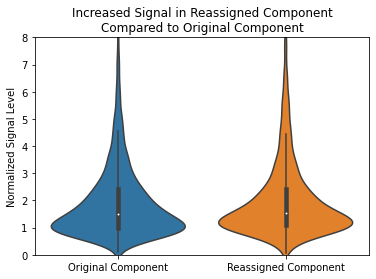

In [320]:
fig = plt.figure()
fig.patch.set_facecolor('white')

sns.violinplot(x=max_violin_x_data, y=max_violin_y_data, scale='count', gridsize=1000, linewidth=1.5)
plt.ylim([0, 8])
# plt.yticks(np.arange(30)[::2])


plt.xticks([0, 1], ['Original Component', 'Reassigned Component'])
plt.ylabel('Normalized Signal Level')
plt.title('Increased Signal in Reassigned Component\nCompared to Original Component')

In [72]:
heatmap_mixture_all_cycles_top_comp_comparison_sum = np.sum(heatmap_mixture_all_cycles_top_comp_comparison, axis=0)
# heatmap_mixture_all_cycles_top_comp_random_sum = np.sum(heatmap_mixture_all_cycles_top_comp_random, axis=0)
print(np.sum(heatmap_mixture_all_cycles_top_comp_comparison_sum))

5767


In [94]:
# heatmap_mixture_all_cycles_top_comp_comparison_ogsum = np.sum(heatmap_mixture_all_cycles_top_comp_comparison_sum, axis=0)
# heatmap_mixture_all_cycles_top_comp_random_ogsum = np.sum(heatmap_mixture_all_cycles_top_comp_random_sum, axis=0)

In [128]:
heatmap_mixture_all_cycles_top_comp_pvals = np.zeros((16, 16), dtype=float)
for original_comp in range(16):
    for new_comp in range(16):
        
        from_og_to_new = len(changed_dhss_original_comp[0][((changed_dhss_original_comp[0]==original_comp) & 
                                                            (changed_dhss_new_comp[0]==new_comp))])
        from_og_to_notnew = len(changed_dhss_original_comp[0][((changed_dhss_original_comp[0]==original_comp) & 
                                                               (changed_dhss_new_comp[0]!=new_comp))])
        from_notog_to_new = len(changed_dhss_original_comp[0][((changed_dhss_original_comp[0]!=original_comp) & 
                                                               (changed_dhss_new_comp[0]==new_comp))])
        from_notog_to_notnew = len(changed_dhss_original_comp[0][((changed_dhss_original_comp[0]!=original_comp) & 
                                                                  (changed_dhss_new_comp[0]!=new_comp))])
        contingency = np.array([[from_og_to_new, from_og_to_notnew], 
                                [from_notog_to_new, from_notog_to_notnew]])
#         print(np.sum(contingency))
        odds, pval = fisher_exact(contingency)
        if original_comp==new_comp:
            pval=np.nan
        heatmap_mixture_all_cycles_top_comp_pvals[new_comp, original_comp]=pval

In [124]:
# original_comp = 1
# new_comp = 0
# from_og_to_new = len(changed_dhss_original_comp[0][((changed_dhss_original_comp[0]==original_comp) & 
#                                                     (changed_dhss_new_comp[0]==new_comp))])
# from_og_to_notnew = len(changed_dhss_original_comp[0][((changed_dhss_original_comp[0]==original_comp) & 
#                                                        (changed_dhss_new_comp[0]!=new_comp))])
# from_notog_to_new = len(changed_dhss_original_comp[0][((changed_dhss_original_comp[0]!=original_comp) & 
#                                                        (changed_dhss_new_comp[0]==new_comp))])
# from_notog_to_notnew = len(changed_dhss_original_comp[0][((changed_dhss_original_comp[0]!=original_comp) & 
#                                                           (changed_dhss_new_comp[0]!=new_comp))])
# contingency = np.array([[from_og_to_new, from_og_to_notnew], 
#                         [from_notog_to_new, from_notog_to_notnew]])
# odds, pval = fisher_exact(contingency)
# print(pval)
# contingency

In [105]:
# heatmap_mixture_all_cycles_top_comp_pvals = np.zeros((16, 16), dtype=float)
# for original_comp in range(16):
#     for new_comp in range(16):
#         flip_new = heatmap_mixture_all_cycles_top_comp_comparison_sum[new_comp, original_comp]
#         flip_not_new = heatmap_mixture_all_cycles_top_comp_comparison_ogsum[original_comp] - flip_new
#         random_new = heatmap_mixture_all_cycles_top_comp_random_sum[new_comp, original_comp]
#         random_not_new = heatmap_mixture_all_cycles_top_comp_random_ogsum[original_comp] - random_new
#         contingency = [[flip_new, random_new], [flip_not_new, random_not_new]]
#         odds, pval = fisher_exact(contingency)
#         heatmap_mixture_all_cycles_top_comp_pvals[new_comp, original_comp]=pval

Text(0.5, 1.07, 'NMF Based Call Correction Results in Significant DHS Component Reassignments')

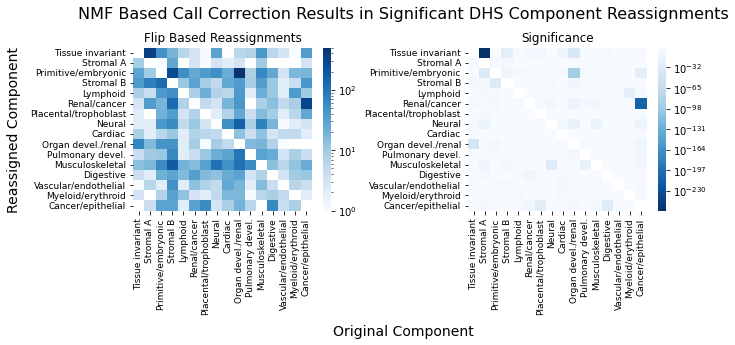

In [115]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 3))
# fig.tight_layout()
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.5, hspace=0)
fig.patch.set_facecolor('white')

axes = axes.ravel()
sns.heatmap(heatmap_mixture_all_cycles_top_comp_comparison_sum, ax=axes[0], xticklabels=comps_for_heatmap_no_spaces, yticklabels=comps_for_heatmap_no_spaces, cmap='Blues', cbar=True, norm=LogNorm(vmax=500)) # 
axes[0].set_xticklabels(comps_for_heatmap_no_spaces, fontsize=9)
axes[0].set_yticklabels(comps_for_heatmap_no_spaces, fontsize=9)


sns.heatmap(heatmap_mixture_all_cycles_top_comp_pvals, ax=axes[1], xticklabels=comps_for_heatmap_no_spaces, yticklabels=comps_for_heatmap_no_spaces, cmap='Blues_r', cbar=True, norm=LogNorm()) # 
axes[1].set_xticklabels(comps_for_heatmap_no_spaces, fontsize=9)
axes[1].set_yticklabels(comps_for_heatmap_no_spaces, fontsize=9)

axes[0].set_title('Flip Based Reassignments')
axes[1].set_title('Significance')



fig.text(-0.05, 0.5, 'Reassigned Component', va='center', rotation='vertical', fontsize=14)
fig.text(0.5, -0.45, 'Original Component', ha='center', fontsize=14)
plt.suptitle('NMF Based Call Correction Results in Significant DHS Component Reassignments', fontsize=16, x=0.5, y=1.07)

In [104]:
#from "all" analysis
dhss_1_to_0 = changed_dhss_all_cycles[0][((changed_dhss_original_comp[0]==1) & (changed_dhss_new_comp[0]==0))]
numflips_1_to_0 = changed_dhss_numflips[0][((changed_dhss_original_comp[0]==1) & (changed_dhss_new_comp[0]==0))]

dhss_9_to_2 = changed_dhss_all_cycles[0][((changed_dhss_original_comp[0]==9) & (changed_dhss_new_comp[0]==2))]
numflips_9_to_2 = changed_dhss_numflips[0][((changed_dhss_original_comp[0]==9) & (changed_dhss_new_comp[0]==2))]

dhss_15_to_5 = changed_dhss_all_cycles[0][((changed_dhss_original_comp[0]==15) & (changed_dhss_new_comp[0]==5))]
numflips_15_to_5 = changed_dhss_numflips[0][((changed_dhss_original_comp[0]==15) & (changed_dhss_new_comp[0]==5))]

#from "flip based" analysis but with all reassignments
dhss_3_to_2 = changed_dhss_all_cycles[0][((changed_dhss_original_comp[0]==3) & (changed_dhss_new_comp[0]==2))]
numflips_3_to_2 = changed_dhss_numflips[0][((changed_dhss_original_comp[0]==3) & (changed_dhss_new_comp[0]==2))]

dhss_2_to_3 = changed_dhss_all_cycles[0][((changed_dhss_original_comp[0]==2) & (changed_dhss_new_comp[0]==3))]
numflips_2_to_3 = changed_dhss_numflips[0][((changed_dhss_original_comp[0]==2) & (changed_dhss_new_comp[0]==3))]

dhss_6_to_15 = changed_dhss_all_cycles[0][((changed_dhss_original_comp[0]==6) & (changed_dhss_new_comp[0]==15))]
numflips_6_to_15 = changed_dhss_numflips[0][((changed_dhss_original_comp[0]==6) & (changed_dhss_new_comp[0]==15))]

In [105]:
numflips_1_to_0_sorted = numflips_1_to_0[np.argsort(-numflips_1_to_0)]
dhss_1_to_0_sorted = dhss_1_to_0[np.argsort(-numflips_1_to_0)]

numflips_9_to_2_sorted = numflips_9_to_2[np.argsort(-numflips_9_to_2)]
dhss_9_to_2_sorted = dhss_9_to_2[np.argsort(-numflips_9_to_2)]

numflips_15_to_5_sorted = numflips_15_to_5[np.argsort(-numflips_15_to_5)]
dhss_15_to_5_sorted = dhss_15_to_5[np.argsort(-numflips_15_to_5)]

numflips_3_to_2_sorted = numflips_3_to_2[np.argsort(-numflips_3_to_2)]
dhss_3_to_2_sorted = dhss_3_to_2[np.argsort(-numflips_3_to_2)]

numflips_2_to_3_sorted = numflips_2_to_3[np.argsort(-numflips_2_to_3)]
dhss_2_to_3_sorted = dhss_2_to_3[np.argsort(-numflips_2_to_3)]

numflips_6_to_15_sorted = numflips_6_to_15[np.argsort(-numflips_6_to_15)]
dhss_6_to_15_sorted = dhss_6_to_15[np.argsort(-numflips_6_to_15)]

In [106]:
dhss_1_to_0_sorted_chrm = np.array(DHS_metadata.loc[dhss_1_to_0_sorted]['seqname'])
dhss_1_to_0_sorted_start = np.array(DHS_metadata.loc[dhss_1_to_0_sorted]['start'])
dhss_1_to_0_sorted_end = np.array(DHS_metadata.loc[dhss_1_to_0_sorted]['end'])

dhss_9_to_2_sorted_chrm = np.array(DHS_metadata.loc[dhss_9_to_2_sorted]['seqname'])
dhss_9_to_2_sorted_start = np.array(DHS_metadata.loc[dhss_9_to_2_sorted]['start'])
dhss_9_to_2_sorted_end = np.array(DHS_metadata.loc[dhss_9_to_2_sorted]['end'])

dhss_15_to_5_sorted_chrm = np.array(DHS_metadata.loc[dhss_15_to_5_sorted]['seqname'])
dhss_15_to_5_sorted_start = np.array(DHS_metadata.loc[dhss_15_to_5_sorted]['start'])
dhss_15_to_5_sorted_end = np.array(DHS_metadata.loc[dhss_15_to_5_sorted]['end'])

dhss_3_to_2_sorted_chrm = np.array(DHS_metadata.loc[dhss_3_to_2_sorted]['seqname'])
dhss_3_to_2_sorted_start = np.array(DHS_metadata.loc[dhss_3_to_2_sorted]['start'])
dhss_3_to_2_sorted_end = np.array(DHS_metadata.loc[dhss_3_to_2_sorted]['end'])

dhss_2_to_3_sorted_chrm = np.array(DHS_metadata.loc[dhss_2_to_3_sorted]['seqname'])
dhss_2_to_3_sorted_start = np.array(DHS_metadata.loc[dhss_2_to_3_sorted]['start'])
dhss_2_to_3_sorted_end = np.array(DHS_metadata.loc[dhss_2_to_3_sorted]['end'])

dhss_6_to_15_sorted_chrm = np.array(DHS_metadata.loc[dhss_6_to_15_sorted]['seqname'])
dhss_6_to_15_sorted_start = np.array(DHS_metadata.loc[dhss_6_to_15_sorted]['start'])
dhss_6_to_15_sorted_end = np.array(DHS_metadata.loc[dhss_6_to_15_sorted]['end'])

In [101]:
# 1 to 0
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_threshold_flip_01thresh_all_reassigned_DHSs_1_to_0_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(dhss_1_to_0_sorted_chrm[i] + '\t' + str(dhss_1_to_0_sorted_start[i]) + '\t' + str(dhss_1_to_0_sorted_end[i]) + '\t' + str(numflips_1_to_0_sorted[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_threshold_flip_01thresh_all_reassigned_DHSs_1_to_0_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_threshold_flip_01thresh_all_reassigned_DHSs_1_to_0_by_numflips_CT20220408.bed


In [102]:
# 9 to 2
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_threshold_flip_01thresh_all_reassigned_DHSs_9_to_2_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(dhss_9_to_2_sorted_chrm[i] + '\t' + str(dhss_9_to_2_sorted_start[i]) + '\t' + str(dhss_9_to_2_sorted_end[i]) + '\t' + str(numflips_9_to_2_sorted[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_threshold_flip_01thresh_all_reassigned_DHSs_9_to_2_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_threshold_flip_01thresh_all_reassigned_DHSs_9_to_2_by_numflips_CT20220408.bed


In [109]:
# 15 to 5
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_threshold_flip_01thresh_all_reassigned_DHSs_15_to_5_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(dhss_15_to_5_sorted_chrm[i] + '\t' + str(dhss_15_to_5_sorted_start[i]) + '\t' + str(dhss_15_to_5_sorted_end[i]) + '\t' + str(numflips_15_to_5_sorted[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_threshold_flip_01thresh_all_reassigned_DHSs_15_to_5_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_threshold_flip_01thresh_all_reassigned_DHSs_15_to_5_by_numflips_CT20220408.bed


In [107]:
# 3 to 2
#from "flip based" analysis but with all reassignments
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_threshold_flip_01thresh_all_reassigned_DHSs_3_to_2_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(dhss_3_to_2_sorted_chrm[i] + '\t' + str(dhss_3_to_2_sorted_start[i]) + '\t' + str(dhss_3_to_2_sorted_end[i]) + '\t' + str(numflips_3_to_2_sorted[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_threshold_flip_01thresh_all_reassigned_DHSs_3_to_2_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_threshold_flip_01thresh_all_reassigned_DHSs_3_to_2_by_numflips_CT20220408.bed


In [110]:
# 2 to 3
#from "flip based" analysis but with all reassignments
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_threshold_flip_01thresh_all_reassigned_DHSs_2_to_3_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(dhss_2_to_3_sorted_chrm[i] + '\t' + str(dhss_2_to_3_sorted_start[i]) + '\t' + str(dhss_2_to_3_sorted_end[i]) + '\t' + str(numflips_2_to_3_sorted[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_threshold_flip_01thresh_all_reassigned_DHSs_2_to_3_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_threshold_flip_01thresh_all_reassigned_DHSs_2_to_3_by_numflips_CT20220408.bed


In [112]:
# 6 to 15
#from "flip based" analysis but with all reassignments
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_threshold_flip_01thresh_all_reassigned_DHSs_6_to_15_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(55):
    f.write(dhss_6_to_15_sorted_chrm[i] + '\t' + str(dhss_6_to_15_sorted_start[i]) + '\t' + str(dhss_6_to_15_sorted_end[i]) + '\t' + str(numflips_6_to_15_sorted[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_threshold_flip_01thresh_all_reassigned_DHSs_6_to_15_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_threshold_flip_01thresh_all_reassigned_DHSs_6_to_15_by_numflips_CT20220408.bed


In [253]:
#biosamples most Stromal to Tissue invariant DHSs are present in
biosample_df.loc[np.where(np.sum(cycle0_dhs_arr[:, dhss_1_to_0], axis=1)>300)[0]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
387,388,Skin_Melanocytes,NaN,ENCSR518JGY,ENCLB426IYP,ENCBS916SKO,AG8946,LN4360,DS18668,DS19662,...,minElute,80.0,5.2,11450000.0,PBS+A,2011-04-05,32632314,0.3337,78398,78299
493,494,Skin_Melanocytes,NaN,ENCSR518JGY,ENCLB338EOX,ENCBS916SKO,AG8850,LN10006,DS19662,DS18668,...,NaN,100.0,NaN,8640000.0,PBS+A,40730,34911631,0.3337,72476,72389
494,495,Skin_Melanocytes,NaN,ENCSR434OBM,ENCLB008CKM,ENCBS425NOG,AG8849,LN10007,DS18590,DS18601,...,NaN,80.0,NaN,5510000.0,PBS+A,2011-03-29,193927893,0.5569,184832,184464


In [281]:
changed_dhss_with_flip = []
for dhs in changed_dhss_all_cycles[0]:
    if ((dhs in removed_DHS_inds) | (dhs in added_DHS_inds)):
        changed_dhss_with_flip.append(dhs)
changed_dhss_with_flip = np.array(changed_dhss_with_flip)

In [286]:
#number of changed DHSs that experience a flip
len(changed_dhss_with_flip)/np.sum(heatmap_mixture_all_cycles_top_comp_comparison_sum)

0.27171839778047513

In [280]:
cycle0_dhs_arr_sum = np.sum(cycle0_dhs_arr, axis=0)
cycle1_dhs_arr_sum = np.sum(cycle1_dhs_arr, axis=0)

In [269]:
removed_DHS_inds = removed_flat_inds_all_cycles[0]%n_DHSs
added_DHS_inds = added_flat_inds_all_cycles[0]%n_DHSs

In [171]:
#finding DHSs in each component before and after flipping (excluding DHSs that reassign from comp 1 to comp 0)
cycle0_dhss_1 = np.sort(list(set(np.where(mixture_all_cycles_top_comp[0]==1)[0]) - set(dhss_1_to_0)))
cycle1_dhss_1 = np.where(mixture_all_cycles_top_comp[1]==1)[0]

cycle0_dhss_0 = np.where(mixture_all_cycles_top_comp[0]==0)[0]
cycle1_dhss_0 = np.sort(list(set(np.where(mixture_all_cycles_top_comp[1]==0)[0]) - set(dhss_1_to_0)))

In [178]:
cycle0_dhss_1_to_0_numbiosamples = cycle0_dhs_arr_sum[dhss_1_to_0]
cycle0_dhss_1_numbiosamples = cycle0_dhs_arr_sum[cycle0_dhss_1]
cycle0_dhss_0_numbiosamples = cycle0_dhs_arr_sum[cycle0_dhss_0]

cycle1_dhss_1_to_0_numbiosamples = cycle1_dhs_arr_sum[dhss_1_to_0]
cycle1_dhss_1_numbiosamples = cycle1_dhs_arr_sum[cycle1_dhss_1]
cycle1_dhss_0_numbiosamples = cycle1_dhs_arr_sum[cycle1_dhss_0]

Text(0.5, 1.1, 'Number of Biosamples Present in Each DHS\nReconstruction Threshold = 0.0/1.0')

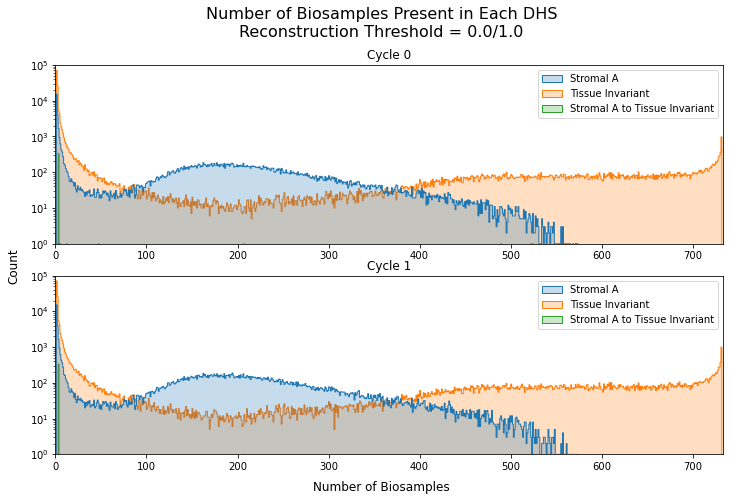

In [258]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(10,6))
fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=None, hspace=0.4)

df0 = pd.DataFrame([cycle0_dhss_1_numbiosamples, cycle0_dhss_0_numbiosamples, cycle0_dhss_1_to_0_numbiosamples], index=['Stromal A', 'Tissue Invariant', 'Stromal A to Tissue Invariant']).transpose()
t1 = sns.histplot(data=df0, ax=axes[0], bins=np.arange(733), element='step')
# t1 = sns.kdeplot(data=df0, ax=axes[0], gridsize=733)
axes[0].set_title('Cycle 0', fontsize=12)

df1 = pd.DataFrame([cycle1_dhss_1_numbiosamples, cycle1_dhss_0_numbiosamples, cycle1_dhss_1_to_0_numbiosamples], index=['Stromal A', 'Tissue Invariant', 'Stromal A to Tissue Invariant']).transpose()
t1 = sns.histplot(data=df1, ax=axes[1], bins=np.arange(733), element='step')
# t1 = sns.kdeplot(data=df1, ax=axes[1], gridsize=733)
axes[1].set_title('Cycle 1', fontsize=12)

axes[0].set_xlim([0, 733])
axes[1].set_xlim([0, 733])
axes[0].set_ylim([1, 100000])
axes[1].set_ylim([1, 100000])
axes[0].set_yscale('log')
axes[1].set_yscale('log')
axes[0].set_ylabel(None)
axes[1].set_ylabel(None)

fig.text(0.5, -0.02, 'Number of Biosamples', ha='center', fontsize=12)
fig.text(-0.02, 0.5, 'Count', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Number of Biosamples Present in Each DHS\nReconstruction Threshold = 0.0/1.0', fontsize=16, x=0.5, y=1.1)

In [130]:
dhss_1_to_0_identifier = np.array(DHS_metadata.loc[dhss_1_to_0]['identifier'])
# dhss_1_to_0_0mean = np.array(all_comps_average_signal.loc[dhss_1_to_0_identifier]['comp0 mean'])
# dhss_1_to_0_0mean_sorted_inds = np.argsort(-dhss_1_to_0_0mean)
# dhss_1_to_0_0mean_sorted = dhss_1_to_0_0mean[dhss_1_to_0_0mean_sorted_inds[:100]]
dhss_1_to_0_chrm = np.array(DHS_metadata.loc[dhss_1_to_0]['seqname'])[dhss_1_to_0_0mean_sorted_inds[:100]]
dhss_1_to_0_start = np.array(DHS_metadata.loc[dhss_1_to_0]['start'])[dhss_1_to_0_0mean_sorted_inds[:100]]
dhss_1_to_0_end = np.array(DHS_metadata.loc[dhss_1_to_0]['end'])[dhss_1_to_0_0mean_sorted_inds[:100]]
# dhss_1_to_0_meansignal = np.array(DHS_metadata.loc[dhss_1_to_0]['mean_signal'])[dhss_1_to_0_0mean_sorted_inds[:100]]

dhss_9_to_2_identifier = np.array(DHS_metadata.loc[dhss_9_to_2]['identifier'])
# dhss_9_to_2_2mean = np.array(all_comps_average_signal.loc[dhss_9_to_2_identifier]['comp2 mean'])
# dhss_9_to_2_2mean_sorted_inds = np.argsort(-dhss_9_to_2_2mean)
# dhss_9_to_2_2mean_sorted = dhss_9_to_2_2mean[dhss_9_to_2_2mean_sorted_inds[:100]]
dhss_9_to_2_chrm = np.array(DHS_metadata.loc[dhss_9_to_2]['seqname'])[dhss_9_to_2_2mean_sorted_inds[:100]]
dhss_9_to_2_start = np.array(DHS_metadata.loc[dhss_9_to_2]['start'])[dhss_9_to_2_2mean_sorted_inds[:100]]
dhss_9_to_2_end = np.array(DHS_metadata.loc[dhss_9_to_2]['end'])[dhss_9_to_2_2mean_sorted_inds[:100]]
# dhss_9_to_2_meansignal = np.array(DHS_metadata.loc[dhss_9_to_2]['mean_signal'])[dhss_9_to_2_2mean_sorted_inds[:100]]

dhss_15_to_5_identifier = np.array(DHS_metadata.loc[dhss_15_to_5]['identifier'])
# dhss_15_to_5_5mean = np.array(all_comps_average_signal.loc[dhss_15_to_5_identifier]['comp5 mean'])
# dhss_15_to_5_5mean_sorted_inds = np.argsort(-dhss_15_to_5_5mean)
# dhss_15_to_5_5mean_sorted = dhss_15_to_5_5mean[dhss_15_to_5_5mean_sorted_inds[:100]]
dhss_15_to_5_chrm = np.array(DHS_metadata.loc[dhss_15_to_5]['seqname'])[dhss_15_to_5_5mean_sorted_inds[:100]]
dhss_15_to_5_start = np.array(DHS_metadata.loc[dhss_15_to_5]['start'])[dhss_15_to_5_5mean_sorted_inds[:100]]
dhss_15_to_5_end = np.array(DHS_metadata.loc[dhss_15_to_5]['end'])[dhss_15_to_5_5mean_sorted_inds[:100]]
# dhss_15_to_5_meansignal = np.array(DHS_metadata.loc[dhss_15_to_5]['mean_signal'])[dhss_15_to_5_5mean_sorted_inds[:100]]

NameError: name 'all_comps_average_signal' is not defined

In [187]:
# 1 to 0
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_threshold_flip_01thresh_reassigned_DHSs_1_to_0_by_meansignal_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(dhss_1_to_0_chrm[i] + '\t' + str(dhss_1_to_0_start[i]) + '\t' + str(dhss_1_to_0_end[i]) + '\t' + str(dhss_1_to_0_0mean_sorted[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_threshold_flip_01thresh_reassigned_DHSs_1_to_0_by_meansignal_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_threshold_flip_01thresh_reassigned_DHSs_1_to_0_by_meansignal_CT20220404.bed


In [188]:
# 9 to 2
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_threshold_flip_01thresh_reassigned_DHSs_9_to_2_by_meansignal_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(dhss_9_to_2_chrm[i] + '\t' + str(dhss_9_to_2_start[i]) + '\t' + str(dhss_9_to_2_end[i]) + '\t' + str(dhss_9_to_2_2mean_sorted[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_threshold_flip_01thresh_reassigned_DHSs_9_to_2_by_meansignal_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_threshold_flip_01thresh_reassigned_DHSs_9_to_2_by_meansignal_CT20220404.bed


In [189]:
# 15 to 5
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_threshold_flip_01thresh_reassigned_DHSs_15_to_5_by_meansignal_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(dhss_15_to_5_chrm[i] + '\t' + str(dhss_15_to_5_start[i]) + '\t' + str(dhss_15_to_5_end[i]) + '\t' + str(dhss_15_to_5_5mean_sorted[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_threshold_flip_01thresh_reassigned_DHSs_15_to_5_by_meansignal_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_threshold_flip_01thresh_reassigned_DHSs_15_to_5_by_meansignal_CT20220404.bed


Text(0.5, 1.0, 'Reassigned DHSs by Top Mixture Loading Component\nReconstruction Threshold = 0.0/1.0')

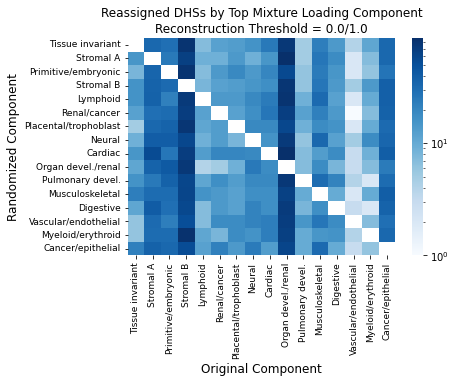

In [46]:
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap_no_spaces = ['Tissue invariant','Stromal A', 'Primitive/embryonic', 'Stromal B', 'Lymphoid', 'Renal/cancer', 'Placental/trophoblast', 'Neural', 'Cardiac', 'Organ devel./renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular/endothelial', 'Myeloid/erythroid', 'Cancer/epithelial']

fig = plt.figure()
fig.patch.set_facecolor('white')

ax = sns.heatmap(heatmap_mixture_all_cycles_top_comp_random_sum, xticklabels=comps_for_heatmap_no_spaces, yticklabels=comps_for_heatmap_no_spaces, cmap='Blues', cbar=True, norm=LogNorm()) # 
ax.set_xticklabels(comps_for_heatmap_no_spaces, fontsize=9)
ax.set_yticklabels(comps_for_heatmap_no_spaces, fontsize=9)

ax.set_ylabel('Randomized Component', fontsize=12)
ax.set_xlabel('Original Component', fontsize=12)
ax.set_title('Reassigned DHSs by Top Mixture Loading Component\nReconstruction Threshold = 0.0/1.0')

Text(0.5, 1.0, 'Reassigned DHSs by Top Mixture Loading Component\nReconstruction Threshold = 0.0/1.0')

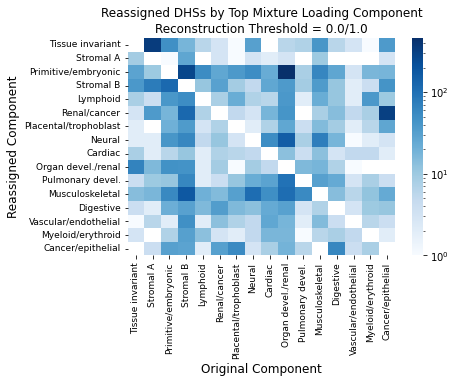

In [36]:
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap_no_spaces = ['Tissue invariant','Stromal A', 'Primitive/embryonic', 'Stromal B', 'Lymphoid', 'Renal/cancer', 'Placental/trophoblast', 'Neural', 'Cardiac', 'Organ devel./renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular/endothelial', 'Myeloid/erythroid', 'Cancer/epithelial']

fig = plt.figure()
fig.patch.set_facecolor('white')

ax = sns.heatmap(heatmap_mixture_all_cycles_top_comp_comparison_sum, xticklabels=comps_for_heatmap_no_spaces, yticklabels=comps_for_heatmap_no_spaces, cmap='Blues', cbar=True, norm=LogNorm()) # 
ax.set_xticklabels(comps_for_heatmap_no_spaces, fontsize=9)
ax.set_yticklabels(comps_for_heatmap_no_spaces, fontsize=9)

ax.set_ylabel('Reassigned Component', fontsize=12)
ax.set_xlabel('Original Component', fontsize=12)
ax.set_title('Reassigned DHSs by Top Mixture Loading Component\nReconstruction Threshold = 0.0/1.0')

In [98]:
#for heatmap of all DHSs
heatmap_mixture_all_cycles_top_comp_comparison_all_DHSs = np.zeros((1, 16,16), dtype=int)

all_dhss_all_cycles = []
all_dhss_original_comp = []
all_dhss_new_comp = []

for i in range(1):
    all_dhss_1_cycle = []
    original_comp = []
    new_comp = []
    
    for comp1, comp0, dhs in zip(mixture_all_cycles_top_comp[i+1], 
                                 mixture_all_cycles_top_comp[i], 
                                 range(len(mixture_all_cycles_top_comp[0]))):
        if ((~np.isnan(comp0)) and (~np.isnan(comp1))):
            comp0 = comp0.astype(int)
            comp1 = comp1.astype(int)
            heatmap_mixture_all_cycles_top_comp_comparison_all_DHSs[i, comp1, comp0] += 1
            all_dhss_1_cycle.append(dhs)
            original_comp.append(comp0)
            new_comp.append(comp1)
            
    all_dhss_all_cycles.append(np.array(all_dhss_1_cycle))
    all_dhss_original_comp.append(np.array(original_comp))
    all_dhss_new_comp.append(np.array(new_comp))

In [99]:
heatmap_mixture_all_cycles_top_comp_comparison_all_DHSs_sum = np.sum(heatmap_mixture_all_cycles_top_comp_comparison_all_DHSs, axis=0)
np.sum(heatmap_mixture_all_cycles_top_comp_comparison_all_DHSs_sum)

3591898

In [26]:
np.sum(heatmap_mixture_all_cycles_top_comp_comparison_sum)

5767

In [255]:
basis_all_cycles_top_comp = np.argmax(basis_all_cycles, axis=2)

In [72]:
#for heatmap of all biosamples
heatmap_basis_all_cycles_top_comp_comparison = np.zeros((1, 16,16), dtype=int)

for i in range(1):
    for comp1, comp0, biosample in zip(basis_all_cycles_top_comp[i+1], 
                                 basis_all_cycles_top_comp[i], 
                                 range(len(basis_all_cycles_top_comp[0]))):
        if ((~np.isnan(comp0)) and (~np.isnan(comp1))):
            comp0 = comp0.astype(int)
            comp1 = comp1.astype(int)
            heatmap_basis_all_cycles_top_comp_comparison[i, comp1, comp0] += 1
            if comp0 != comp1:
                print(biosample, comp0, comp1)

411 0 9
486 0 9
531 0 9
719 11 0
728 9 8


In [9]:
cycle0_dhs_arr = np.load('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38_bool_array.npy').astype(int)

In [151]:
filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle1_CT20220323.npz'
cycle1_dhs_arr = np.load(filename)['new_dhs_array'].astype(int)

In [107]:
removed_biosample_inds = removed_flat_inds_all_cycles[0]//n_DHSs
added_biosample_inds = added_flat_inds_all_cycles[0]//n_DHSs
removed_DHS_inds = removed_flat_inds_all_cycles[0]%n_DHSs

In [102]:
print(basis_all_cycles[0, 411, :])
print(basis_all_cycles[1, 411, :])
print(np.sum(cycle0_dhs_arr[411, :]), np.sum(cycle1_dhs_arr[411, :]))
print(len(np.where(added_biosample_inds==411)[0]), len(np.where(removed_biosample_inds==411)[0]))

[1.6800407 0.        0.        0.        0.        0.        0.
 0.        0.        1.6576077 0.        0.        0.        0.
 0.        0.       ]
[1.6756366 0.        0.        0.        0.        0.        0.
 0.        0.        1.6767769 0.        0.        0.        0.
 0.        0.       ]
46045 46040
10 15


In [103]:
print(basis_all_cycles[0, 486, :])
print(basis_all_cycles[1, 486, :])
print(np.sum(cycle0_dhs_arr[486, :]), np.sum(cycle1_dhs_arr[486, :]))
print(len(np.where(added_biosample_inds==486)[0]), len(np.where(removed_biosample_inds==486)[0]))

[1.7151908 0.        0.        0.        0.        0.        0.
 0.        0.        1.7093202 0.        0.        0.        0.
 0.        0.       ]
[1.7115053 0.        0.        0.        0.        0.        0.
 0.        0.        1.7278854 0.        0.        0.        0.
 0.        0.       ]
46484 46489
17 12


In [104]:
print(basis_all_cycles[0, 531, :])
print(basis_all_cycles[1, 531, :])
print(np.sum(cycle0_dhs_arr[531, :]), np.sum(cycle1_dhs_arr[531, :]))
print(len(np.where(added_biosample_inds==531)[0]), len(np.where(removed_biosample_inds==531)[0]))

[1.8357347 0.        0.        0.        0.        0.        0.
 0.        0.        1.8236554 0.        0.        0.        0.
 0.        0.       ]
[1.8339665 0.        0.        0.        0.        0.        0.
 0.        0.        1.8418158 0.        0.        0.        0.
 0.        0.       ]
51894 51913
41 22


In [105]:
print(basis_all_cycles[0, 719, :])
print(basis_all_cycles[1, 719, :])
print(np.sum(cycle0_dhs_arr[719, :]), np.sum(cycle1_dhs_arr[719, :]))
print(len(np.where(added_biosample_inds==719)[0]), len(np.where(removed_biosample_inds==719)[0]))

[1.1516066  0.         0.7832982  0.         0.         0.
 0.00264555 0.         0.         0.2738395  0.         1.1576426
 0.         0.         0.         0.        ]
[1.1550648  0.         0.7859617  0.         0.         0.
 0.00162611 0.         0.         0.2712984  0.         1.15341
 0.         0.         0.         0.        ]
110550 110120
0 430


In [115]:
removed_DHSs_from_719 = removed_DHS_inds[np.where(removed_biosample_inds==719)[0]]
np.where(mixture_all_cycles_top_comp[1, removed_DHSs_from_719]==0)

(array([], dtype=int64),)

In [120]:
cycle0_dhs_arr_biosample_sum = np.sum(cycle0_dhs_arr, axis=1)
cycle1_dhs_arr_biosample_sum = np.sum(cycle1_dhs_arr, axis=1)

In [126]:
dhs_arr_biosample_sum_netchange = cycle1_dhs_arr_biosample_sum-cycle0_dhs_arr_biosample_sum
# (np.abs(dhs_arr_biosample_sum_netchange))

In [106]:
print(basis_all_cycles[0, 728, :])
print(basis_all_cycles[1, 728, :])
print(np.sum(cycle0_dhs_arr[728, :]), np.sum(cycle1_dhs_arr[728, :]))
print(len(np.where(added_biosample_inds==728)[0]), len(np.where(removed_biosample_inds==728)[0]))

[0.8970499  0.49900964 0.61669993 0.         0.14826612 0.
 0.8126151  0.02668556 1.119037   1.1276754  0.37428486 0.98447037
 0.4392211  0.         0.         0.        ]
[0.8949108  0.49899223 0.621705   0.         0.14576694 0.
 0.81328446 0.0274605  1.1269095  1.1169735  0.37629232 0.9838836
 0.44105294 0.         0.         0.        ]
112469 112465
1 5


In [31]:
heatmap_basis_all_cycles_top_comp_comparison_sum = np.sum(heatmap_basis_all_cycles_top_comp_comparison, axis=0)
np.sum(heatmap_basis_all_cycles_top_comp_comparison_sum)

733

Text(0.5, 1.0, 'Biosample Component Assignments Remain Mostly Stable')

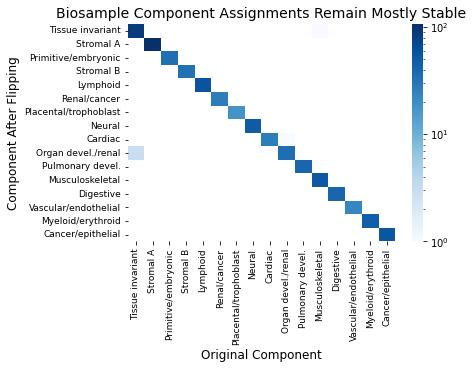

In [32]:
#figure for slide deck
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap_no_spaces = ['Tissue invariant','Stromal A', 'Primitive/embryonic', 'Stromal B', 'Lymphoid', 'Renal/cancer', 'Placental/trophoblast', 'Neural', 'Cardiac', 'Organ devel./renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular/endothelial', 'Myeloid/erythroid', 'Cancer/epithelial']

fig = plt.figure()
fig.patch.set_facecolor('white')

ax = sns.heatmap(heatmap_basis_all_cycles_top_comp_comparison_sum, xticklabels=comps_for_heatmap_no_spaces, yticklabels=comps_for_heatmap_no_spaces, cmap='Blues', cbar=True, norm=LogNorm()) # 
ax.set_xticklabels(comps_for_heatmap_no_spaces, fontsize=9)
ax.set_yticklabels(comps_for_heatmap_no_spaces, fontsize=9)

ax.set_ylabel('Component After Flipping', fontsize=12)
ax.set_xlabel('Original Component', fontsize=12)
ax.set_title('Biosample Component Assignments Remain Mostly Stable', fontsize=14)

Text(0.5, 1.0, 'DHS Component Assignments Remain Mostly Stable')

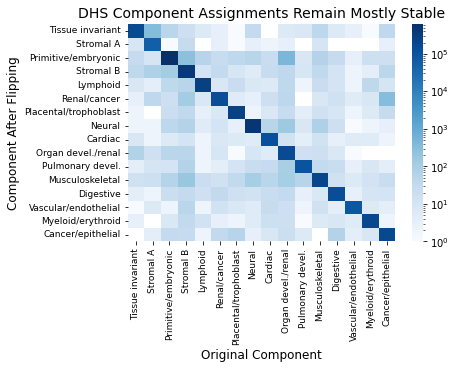

In [100]:
#figure for slide deck
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap_no_spaces = ['Tissue invariant','Stromal A', 'Primitive/embryonic', 'Stromal B', 'Lymphoid', 'Renal/cancer', 'Placental/trophoblast', 'Neural', 'Cardiac', 'Organ devel./renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular/endothelial', 'Myeloid/erythroid', 'Cancer/epithelial']

fig = plt.figure()
fig.patch.set_facecolor('white')

ax = sns.heatmap(heatmap_mixture_all_cycles_top_comp_comparison_all_DHSs_sum, xticklabels=comps_for_heatmap_no_spaces, yticklabels=comps_for_heatmap_no_spaces, cmap='Blues', cbar=True, norm=LogNorm()) # 
ax.set_xticklabels(comps_for_heatmap_no_spaces, fontsize=9)
ax.set_yticklabels(comps_for_heatmap_no_spaces, fontsize=9)

ax.set_ylabel('Component After Flipping', fontsize=12)
ax.set_xlabel('Original Component', fontsize=12)
ax.set_title('DHS Component Assignments Remain Mostly Stable', fontsize=14)

Text(0.42, 0.98, '99.9996% of DHS Component Assignments Remain Stable')

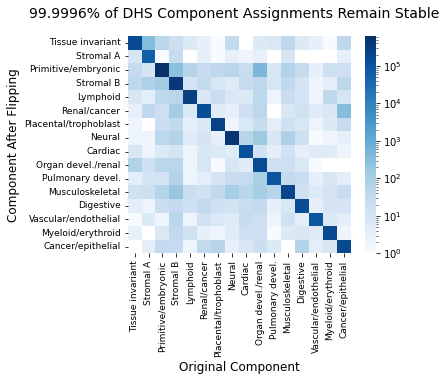

In [101]:
#figure for slide deck
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap_no_spaces = ['Tissue invariant','Stromal A', 'Primitive/embryonic', 'Stromal B', 'Lymphoid', 'Renal/cancer', 'Placental/trophoblast', 'Neural', 'Cardiac', 'Organ devel./renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular/endothelial', 'Myeloid/erythroid', 'Cancer/epithelial']

fig = plt.figure(figsize=(5,4))
fig.patch.set_facecolor('white')

ax = sns.heatmap(heatmap_mixture_all_cycles_top_comp_comparison_all_DHSs_sum, xticklabels=comps_for_heatmap_no_spaces, yticklabels=comps_for_heatmap_no_spaces, cmap='Blues', cbar=True, norm=LogNorm()) # 
ax.set_xticklabels(comps_for_heatmap_no_spaces, fontsize=9)
ax.set_yticklabels(comps_for_heatmap_no_spaces, fontsize=9)

ax.set_ylabel('Component After Flipping', fontsize=12)
ax.set_xlabel('Original Component', fontsize=12)
plt.suptitle(str(np.round((1-(len(heatmap_mixture_all_cycles_top_comp_comparison_sum)/n_DHSs))*100, 4)) + '% of DHS Component Assignments Remain Stable', fontsize=14, x=0.42, y=.98)

Text(0.5, 1.07, 'DHS and Biosample Component Assignments Remain Mostly Stable')

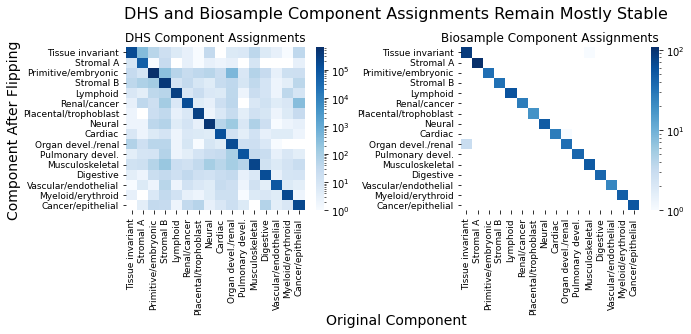

In [70]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 3))
# fig.tight_layout()
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.5, hspace=0)
fig.patch.set_facecolor('white')

axes = axes.ravel()
sns.heatmap(heatmap_mixture_all_cycles_top_comp_comparison_sum, ax=axes[0], xticklabels=comps_for_heatmap_no_spaces, yticklabels=comps_for_heatmap_no_spaces, cmap='Blues', cbar=True, norm=LogNorm()) # 
axes[0].set_xticklabels(comps_for_heatmap_no_spaces, fontsize=9)
axes[0].set_yticklabels(comps_for_heatmap_no_spaces, fontsize=9)

sns.heatmap(heatmap_basis_all_cycles_top_comp_comparison_sum, ax=axes[1], xticklabels=comps_for_heatmap_no_spaces, yticklabels=comps_for_heatmap_no_spaces, cmap='Blues', cbar=True, norm=LogNorm()) # 
axes[1].set_xticklabels(comps_for_heatmap_no_spaces, fontsize=9)
axes[1].set_yticklabels(comps_for_heatmap_no_spaces, fontsize=9)

axes[0].set_title('DHS Component Assignments')
axes[1].set_title('Biosample Component Assignments')


fig.text(-0.04, 0.5, 'Component After Flipping', va='center', rotation='vertical', fontsize=14)
fig.text(0.5, -0.4, 'Original Component', ha='center', fontsize=14)
plt.suptitle('DHS and Biosample Component Assignments Remain Mostly Stable', fontsize=16, x=0.5, y=1.07)

**Flip Based Reassignments**

In [10]:
removed_DHS_inds = removed_flat_inds_all_cycles[0]%n_DHSs
added_DHS_inds = added_flat_inds_all_cycles[0]%n_DHSs

removed_biosample_inds = removed_flat_inds_all_cycles[0]//n_DHSs
added_biosample_inds = added_flat_inds_all_cycles[0]//n_DHSs

In [11]:
mixture_all_cycles_top_comp = np.argmax(mixture_all_cycles, axis=1)

In [12]:
heatmap_mixture_all_cycles_top_comp_comparison_flipbased = np.zeros((1, 16,16), dtype=int)
heatmap_mixture_all_cycles_top_comp_comparison_notflipbased = np.zeros((1, 16,16), dtype=int)

changed_dhss_all_cycles_flipbased = []
changed_dhss_original_comp_flipbased = []
changed_dhss_new_comp_flipbased = []
changed_dhss_numflips_flipbased = []

changed_dhss_all_cycles_notflipbased = []
changed_dhss_original_comp_notflipbased = []
changed_dhss_new_comp_notflipbased = []

for i in range(1):
    changed_dhss_1_cycle_flipbased = []
    original_comp_flipbased = []
    new_comp_flipbased = []
    numflips_flipbased = []
    
    changed_dhss_1_cycle_notflipbased = []
    original_comp_notflipbased = []
    new_comp_notflipbased = []
    
    for comp1, comp0, dhs in zip(mixture_all_cycles_top_comp[i+1], 
                                 mixture_all_cycles_top_comp[i], 
                                 range(len(mixture_all_cycles_top_comp[0]))):
        if ((comp1!=comp0) and (~np.isnan(comp0)) and (~np.isnan(comp1))):
            comp0 = comp0.astype(int)
            comp1 = comp1.astype(int)
            if ((dhs in removed_DHS_inds) | (dhs in added_DHS_inds)):
                heatmap_mixture_all_cycles_top_comp_comparison_flipbased[i, comp1, comp0] += 1
                changed_dhss_1_cycle_flipbased.append(dhs)
                original_comp_flipbased.append(comp0)
                new_comp_flipbased.append(comp1)
                numflips_flipbased.append(len(np.where(removed_DHS_inds==dhs)[0]) + 
                                          len(np.where(added_DHS_inds==dhs)[0]))
            else:
                heatmap_mixture_all_cycles_top_comp_comparison_notflipbased[i, comp1, comp0] += 1
                changed_dhss_1_cycle_notflipbased.append(dhs)
                original_comp_notflipbased.append(comp0)
                new_comp_notflipbased.append(comp1)
            
    changed_dhss_all_cycles_flipbased.append(np.array(changed_dhss_1_cycle_flipbased))
    changed_dhss_original_comp_flipbased.append(np.array(original_comp_flipbased))
    changed_dhss_new_comp_flipbased.append(np.array(new_comp_flipbased))
    changed_dhss_numflips_flipbased.append(np.array(numflips_flipbased))
    
    changed_dhss_all_cycles_notflipbased.append(np.array(changed_dhss_1_cycle_notflipbased))
    changed_dhss_original_comp_notflipbased.append(np.array(original_comp_notflipbased))
    changed_dhss_new_comp_notflipbased.append(np.array(new_comp_notflipbased))

In [14]:
len(changed_dhss_all_cycles_flipbased[0])/(len(changed_dhss_all_cycles_flipbased[0])+len(changed_dhss_all_cycles_notflipbased[0]))

0.27171839778047513

In [14]:
#flip based ratio of new comp to old comp before and after flipping
changed_dhss_cycle0_new_to_old_comp_loading_ratio_flipbased = []
changed_dhss_cycle1_new_to_old_comp_loading_ratio_flipbased = []
for dhs, og_comp, new_comp in zip(changed_dhss_all_cycles_flipbased[0], 
                                  changed_dhss_original_comp_flipbased[0], 
                                  changed_dhss_new_comp_flipbased[0]):
    changed_dhss_cycle0_new_to_old_comp_loading_ratio_flipbased.append(mixture_all_cycles[0, new_comp, dhs] / 
                                                                       mixture_all_cycles[0, og_comp, dhs])
    changed_dhss_cycle1_new_to_old_comp_loading_ratio_flipbased.append(mixture_all_cycles[1, new_comp, dhs] / 
                                                                       mixture_all_cycles[1, og_comp, dhs])
changed_dhss_cycle0_new_to_old_comp_loading_ratio_flipbased = np.array(changed_dhss_cycle0_new_to_old_comp_loading_ratio_flipbased)
changed_dhss_cycle1_new_to_old_comp_loading_ratio_flipbased = np.array(changed_dhss_cycle1_new_to_old_comp_loading_ratio_flipbased)

In [15]:
#non-flip based ratio of new comp to old comp before and after flipping
changed_dhss_cycle0_new_to_old_comp_loading_ratio_notflipbased = []
changed_dhss_cycle1_new_to_old_comp_loading_ratio_notflipbased = []
for dhs, og_comp, new_comp in zip(changed_dhss_all_cycles_notflipbased[0], 
                                  changed_dhss_original_comp_notflipbased[0], 
                                  changed_dhss_new_comp_notflipbased[0]):
    changed_dhss_cycle0_new_to_old_comp_loading_ratio_notflipbased.append(mixture_all_cycles[0, new_comp, dhs] / 
                                                                          mixture_all_cycles[0, og_comp, dhs])
    changed_dhss_cycle1_new_to_old_comp_loading_ratio_notflipbased.append(mixture_all_cycles[1, new_comp, dhs] / 
                                                                          mixture_all_cycles[1, og_comp, dhs])
changed_dhss_cycle0_new_to_old_comp_loading_ratio_notflipbased = np.array(changed_dhss_cycle0_new_to_old_comp_loading_ratio_notflipbased)
changed_dhss_cycle1_new_to_old_comp_loading_ratio_notflipbased = np.array(changed_dhss_cycle1_new_to_old_comp_loading_ratio_notflipbased)

In [25]:
print(np.mean(changed_dhss_cycle0_new_to_old_comp_loading_ratio_notflipbased))
print(np.mean(changed_dhss_cycle0_new_to_old_comp_loading_ratio_flipbased))
print(np.mean(changed_dhss_cycle1_new_to_old_comp_loading_ratio_notflipbased))
print(np.mean(changed_dhss_cycle1_new_to_old_comp_loading_ratio_flipbased))

0.9948042
0.96055514
1.0047675
1.042135


In [45]:
violin_y_data_flipbased = np.append(changed_dhss_cycle0_new_to_old_comp_loading_ratio_flipbased, changed_dhss_cycle1_new_to_old_comp_loading_ratio_flipbased)
violin_x_data_flipbased = np.append(np.zeros(len(changed_dhss_cycle0_new_to_old_comp_loading_ratio_flipbased)), np.ones(len(changed_dhss_cycle1_new_to_old_comp_loading_ratio_flipbased)))

violin_y_data_notflipbased = np.append(changed_dhss_cycle0_new_to_old_comp_loading_ratio_notflipbased, changed_dhss_cycle1_new_to_old_comp_loading_ratio_notflipbased)
violin_x_data_notflipbased = np.append(np.zeros(len(changed_dhss_cycle0_new_to_old_comp_loading_ratio_notflipbased)), np.ones(len(changed_dhss_cycle1_new_to_old_comp_loading_ratio_notflipbased)))

violin_y_data_all = np.append(violin_y_data_flipbased, violin_y_data_notflipbased)
violin_x_data_all = np.append(violin_x_data_flipbased, violin_x_data_notflipbased+2)

Text(0.5, 0.98, 'Flip Based Reassignments Occur with\nGreater Changes in Component Loadings')

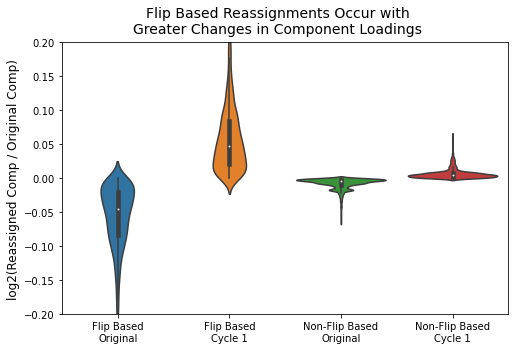

In [71]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(8, 5))
# fig.tight_layout()
fig.patch.set_facecolor('white')

sns.violinplot(x=violin_x_data_all, y=np.log2(violin_y_data_all), ax=axes, scale='count', gridsize=3000, linewidth=1.5)

# sns.violinplot(x=violin_x_data_flipbased, y=violin_y_data_flipbased, ax=axes, scale='count', gridsize=int(len(violin_x_data_flipbased)/2), linewidth=1.5)

# sns.violinplot(x=violin_x_data_notflipbased+2, y=violin_y_data_notflipbased, ax=axes, scale='count', gridsize=int(len(violin_x_data_notflipbased)/2), linewidth=1.5)

axes.set_ylim([-0.2, 0.2])

axes.set_xticks([0, 1, 2, 3])
axes.set_xticklabels(['Flip Based\nOriginal', 'Flip Based\nCycle 1', 'Non-Flip Based\nOriginal', 'Non-Flip Based\nCycle 1'])

fig.text(0.03, 0.5, 'log2(Reassigned Comp / Original Comp)', va='center', rotation='vertical', fontsize=12)
# fig.text(0.5, 0.02, 'Original Component', ha='center', fontsize=12)
plt.suptitle('Flip Based Reassignments Occur with\nGreater Changes in Component Loadings', fontsize=14, x=0.5, y=0.98)

In [34]:
#top 15 biosamples for each component by NMF
top_15_biosample_all_comps = []
for i in range(16):
    top_15_each_comp = np.argsort(-basis_all_cycles[0, :, i])[:15]
    top_15_biosample_all_comps.append(top_15_each_comp)
top_15_biosample_all_comps = np.array(top_15_biosample_all_comps)

In [62]:
#using max signal
original_comp_total_max_signal_flipbased = np.array([])
new_comp_total_max_signal_flipbased = np.array([])
for original_comp in range(16):
    for new_comp in range(16):
        changed_dhss = changed_dhss_all_cycles_flipbased[0][((changed_dhss_original_comp_flipbased[0]==original_comp) & 
                                                             (changed_dhss_new_comp_flipbased[0]==new_comp))]
        if len(changed_dhss)>0:
            max_signal_changed_dhss = DHS_max_signal_array[:, changed_dhss]
            original_comp_signal = np.mean(max_signal_changed_dhss[top_15_biosample_all_comps[original_comp, :], :], axis=0)
            new_comp_signal = np.mean(max_signal_changed_dhss[top_15_biosample_all_comps[new_comp, :], :], axis=0)
            norm_signal = np.mean(max_signal_changed_dhss[top_15_biosample_all_comps.flatten(), :], axis=0)
            original_comp_total_max_signal_flipbased = np.append(original_comp_total_max_signal_flipbased, original_comp_signal/norm_signal)
            new_comp_total_max_signal_flipbased = np.append(new_comp_total_max_signal_flipbased, new_comp_signal/norm_signal)

In [36]:
#using max signal
original_comp_total_max_signal_notflipbased = np.array([])
new_comp_total_max_signal_notflipbased = np.array([])
for original_comp in range(16):
    for new_comp in range(16):
        changed_dhss = changed_dhss_all_cycles_notflipbased[0][((changed_dhss_original_comp_notflipbased[0]==original_comp) & 
                                                                (changed_dhss_new_comp_notflipbased[0]==new_comp))]
        if len(changed_dhss)>0:
            max_signal_changed_dhss = DHS_max_signal_array[:, changed_dhss]
            original_comp_signal = np.mean(max_signal_changed_dhss[top_15_biosample_all_comps[original_comp, :], :], axis=0)
            new_comp_signal = np.mean(max_signal_changed_dhss[top_15_biosample_all_comps[new_comp, :], :], axis=0)
            norm_signal = np.mean(max_signal_changed_dhss[top_15_biosample_all_comps.flatten(), :], axis=0)
            original_comp_total_max_signal_notflipbased = np.append(original_comp_total_max_signal_notflipbased, original_comp_signal/norm_signal)
            new_comp_total_max_signal_notflipbased = np.append(new_comp_total_max_signal_notflipbased, new_comp_signal/norm_signal)

In [24]:
print(np.mean(original_comp_total_max_signal_flipbased))
print(np.mean(new_comp_total_max_signal_flipbased))
print(np.mean(original_comp_total_max_signal_notflipbased))
print(np.mean(new_comp_total_max_signal_notflipbased))

2.392973265889396
2.553551368695766
1.7519398803279902
1.823436519420477


In [81]:
#using max signal from any biosample of the reassigned/original component - 5/20/22
original_comp_max_signal_any_biosample_flipbased = np.array([])
new_comp_max_signal_any_biosample_flipbased = np.array([])
for original_comp in range(16):
    for new_comp in range(16):
        changed_dhss = changed_dhss_all_cycles_flipbased[0][((changed_dhss_original_comp_flipbased[0]==original_comp) & 
                                                             (changed_dhss_new_comp_flipbased[0]==new_comp))]
        #find biosamples
        original_biosamples = np.where(basis_all_cycles_top_comp[0]==original_comp)[0]
        new_biosamples = np.where(basis_all_cycles_top_comp[1]==new_comp)[0]
        #find max signal out of those biosamples for these DHSs
        original_max_signal = np.max(DHS_max_signal_array[:, changed_dhss][original_biosamples, :], axis=0)
        new_max_signal = np.max(DHS_max_signal_array[:, changed_dhss][new_biosamples, :], axis=0)
        original_comp_max_signal_any_biosample_flipbased = np.append(original_comp_max_signal_any_biosample_flipbased, original_max_signal)
        new_comp_max_signal_any_biosample_flipbased = np.append(new_comp_max_signal_any_biosample_flipbased, new_max_signal)
        
comp_max_signal_any_biosample_flipbased_diff = new_comp_max_signal_any_biosample_flipbased-original_comp_max_signal_any_biosample_flipbased

In [82]:
describe(comp_max_signal_any_biosample_flipbased_diff)

DescribeResult(nobs=1567, minmax=(-25.27466, 319.97436999999996), mean=0.4462709859604339, variance=125.86036022392899, skewness=20.696919123275343, kurtosis=540.260415084057)

Text(0.5, 1.0, 'Difference in Max Signal of Top Biosample of the\nOriginal and Reassigned Compoent for Flip Based DHSs')

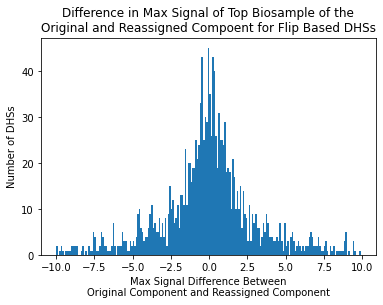

In [83]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(comp_max_signal_any_biosample_flipbased_diff, 
        bins=np.arange(-10, 10, 0.1))

# plt.yscale('log')
plt.xlabel('Max Signal Difference Between\nOriginal Component and Reassigned Component')
plt.ylabel('Number of DHSs')
plt.title('Difference in Max Signal of Top Biosample of the\nOriginal and Reassigned Compoent for Flip Based DHSs')

Text(0.5, 1.0, 'Increased Signal in Flip Based Reassigned Component\nCompared to Original Component')

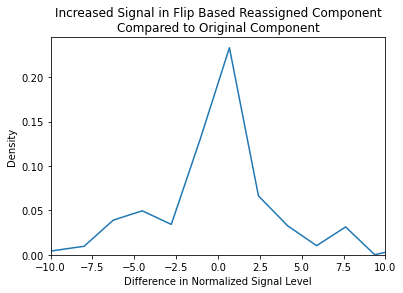

In [74]:
fig = plt.figure()
fig.patch.set_facecolor('white')

sns.kdeplot(comp_max_signal_any_biosample_flipbased_diff, bw_adjust=0.01)
# plt.plot([0, 0], [0, 1])

plt.xlim([-10, 10])
plt.xlabel('Difference in Normalized Signal Level')
plt.ylabel('Density')
plt.title('Increased Signal in Flip Based Reassigned Component\nCompared to Original Component')

In [ ]:
#using max signal from any biosample of the reassigned/original component - 5/20/22
original_comp_max_signal_any_biosample_flipbased = np.array([])
new_comp_max_signal_any_biosample_flipbased = np.array([])
for original_comp in range(16):
    for new_comp in range(16):
        changed_dhss = changed_dhss_all_cycles_flipbased[0][((changed_dhss_original_comp_flipbased[0]==original_comp) & 
                                                             (changed_dhss_new_comp_flipbased[0]==new_comp))]
        #find biosamples
        original_biosamples = np.where(basis_all_cycles_top_comp[0]==original_comp)[0]
        new_biosamples = np.where(basis_all_cycles_top_comp[1]==new_comp)[0]
        #

In [29]:
new_original_max_signal_diff_flipbased = new_comp_total_max_signal_flipbased - original_comp_total_max_signal_flipbased

Text(0.5, 1.0, 'Difference in Max Signal of Top 15 Biosamples of the\nOriginal and Reassigned Compoent for Flip Based DHSs')

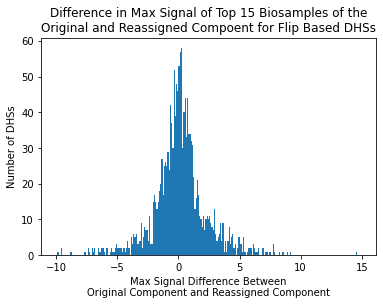

In [41]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(new_original_max_signal_diff_flipbased, 
        bins=np.arange(-10, 15, 0.1))

# plt.yscale('log')
plt.xlabel('Max Signal Difference Between\nOriginal Component and Reassigned Component')
plt.ylabel('Number of DHSs')
plt.title('Difference in Max Signal of Top 15 Biosamples of the\nOriginal and Reassigned Compoent for Flip Based DHSs')

In [31]:
describe(new_original_max_signal_diff_flipbased)

DescribeResult(nobs=1567, minmax=(-9.817783160958648, 14.584356302951594), mean=0.16057810280637036, variance=5.068318448112531, skewness=0.16704326122203428, kurtosis=3.5675737095566227)

Text(0.5, 1.0, 'Increased Signal in Flip Based Reassigned Component\nCompared to Original Component')

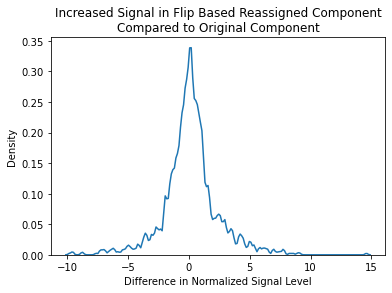

In [50]:
fig = plt.figure()
fig.patch.set_facecolor('white')

sns.kdeplot(new_original_max_signal_diff_flipbased, bw_adjust=0.2)
# plt.plot([0, 0], [0, 1])

# plt.ylim([0, 0.4])
plt.xlabel('Difference in Normalized Signal Level')
plt.ylabel('Density')
plt.title('Increased Signal in Flip Based Reassigned Component\nCompared to Original Component')

In [23]:
max_violin_y_data_flipbased = np.append(original_comp_total_max_signal_flipbased, new_comp_total_max_signal_flipbased)
max_violin_x_data_flipbased = np.append(np.zeros(len(original_comp_total_max_signal_flipbased)), np.ones(len(new_comp_total_max_signal_flipbased)))

max_violin_y_data_notflipbased = np.append(original_comp_total_max_signal_notflipbased, new_comp_total_max_signal_notflipbased)
max_violin_x_data_notflipbased = np.append(np.zeros(len(original_comp_total_max_signal_notflipbased)), np.ones(len(new_comp_total_max_signal_notflipbased)))

max_violin_y_data_all = np.append(max_violin_y_data_flipbased, max_violin_y_data_notflipbased)
max_violin_x_data_all = np.append(max_violin_x_data_flipbased, max_violin_x_data_notflipbased+2)

max_violin_y_data_newonly = np.append(new_comp_total_max_signal_flipbased, new_comp_total_max_signal_notflipbased)
max_violin_x_data_newonly = np.append(np.zeros(len(new_comp_total_max_signal_flipbased)), np.ones(len(new_comp_total_max_signal_notflipbased)))

Text(0.5, 1.0, 'Increased Signal in Flip Based Reassigned Component\nCompared to Original Component')

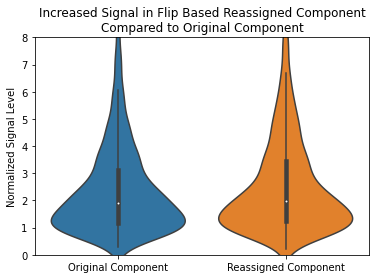

In [25]:
fig = plt.figure()
fig.patch.set_facecolor('white')

sns.violinplot(x=max_violin_x_data_flipbased, y=max_violin_y_data_flipbased, scale='count', gridsize=1000, linewidth=1.5)
plt.ylim([0, 8])
# plt.yticks(np.arange(30)[::2])


plt.xticks([0, 1], ['Original Component', 'Reassigned Component'])
plt.ylabel('Normalized Signal Level')
plt.title('Increased Signal in Flip Based Reassigned Component\nCompared to Original Component')

Text(0.5, 1.0, 'Increased Signal in Non-Flip Based Reassigned Component\nCompared to Original Component')

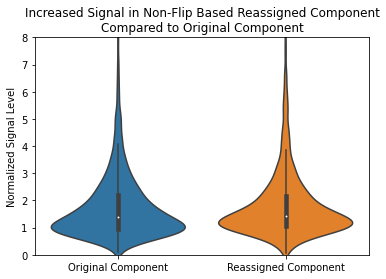

In [24]:
fig = plt.figure()
fig.patch.set_facecolor('white')

sns.violinplot(x=max_violin_x_data_notflipbased, y=max_violin_y_data_notflipbased, scale='count', gridsize=1000, linewidth=1.5)
plt.ylim([0, 8])
# plt.yticks(np.arange(30)[::2])


plt.xticks([0, 1], ['Original Component', 'Reassigned Component'])
plt.ylabel('Normalized Signal Level')
plt.title('Increased Signal in Non-Flip Based Reassigned Component\nCompared to Original Component')

Text(0.5, 1.0, 'Increased Signal in Flip Based Reassignments\nCompared to Non-Flip Based Reassignments')

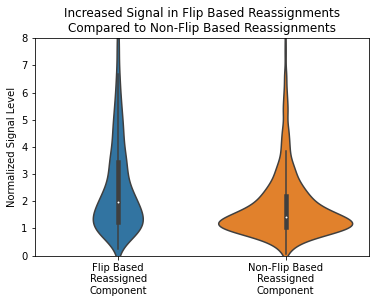

In [25]:
fig = plt.figure()
fig.patch.set_facecolor('white')

sns.violinplot(x=max_violin_x_data_newonly, y=max_violin_y_data_newonly, scale='count', gridsize=1000, linewidth=1.5)
plt.ylim([0, 8])
# plt.yticks(np.arange(30)[::2])


plt.xticks([0, 1], ['Flip Based\nReassigned\nComponent', 'Non-Flip Based\nReassigned\nComponent'])
plt.ylabel('Normalized Signal Level')
plt.title('Increased Signal in Flip Based Reassignments\nCompared to Non-Flip Based Reassignments')

In [26]:
heatmap_mixture_all_cycles_top_comp_comparison_flipbased_sum = np.sum(heatmap_mixture_all_cycles_top_comp_comparison_flipbased, axis=0)
print(np.sum(heatmap_mixture_all_cycles_top_comp_comparison_flipbased_sum))

1567


In [27]:
heatmap_mixture_all_cycles_top_comp_flipbased_pvals = np.zeros((16, 16), dtype=float)
for original_comp in range(16):
    for new_comp in range(16):
        
        from_og_to_new = len(changed_dhss_original_comp_flipbased[0][((changed_dhss_original_comp_flipbased[0]==original_comp) & 
                                                                      (changed_dhss_new_comp_flipbased[0]==new_comp))])
        from_og_to_notnew = len(changed_dhss_original_comp_flipbased[0][((changed_dhss_original_comp_flipbased[0]==original_comp) & 
                                                                         (changed_dhss_new_comp_flipbased[0]!=new_comp))])
        from_notog_to_new = len(changed_dhss_original_comp_flipbased[0][((changed_dhss_original_comp_flipbased[0]!=original_comp) & 
                                                                         (changed_dhss_new_comp_flipbased[0]==new_comp))])
        from_notog_to_notnew = len(changed_dhss_original_comp_flipbased[0][((changed_dhss_original_comp_flipbased[0]!=original_comp) & 
                                                                            (changed_dhss_new_comp_flipbased[0]!=new_comp))])
        contingency = np.array([[from_og_to_new, from_og_to_notnew], 
                                [from_notog_to_new, from_notog_to_notnew]])
#         print(np.sum(contingency))
        odds, pval = fisher_exact(contingency)
        if original_comp==new_comp:
            pval=np.nan
        heatmap_mixture_all_cycles_top_comp_flipbased_pvals[new_comp, original_comp]=pval

In [32]:
np.max(heatmap_mixture_all_cycles_top_comp_comparison_flipbased_sum)

191

Text(0.5, 1.13, 'NMF Based Call Correction Results in Significant\nFlip Based DHS Component Reassignments')

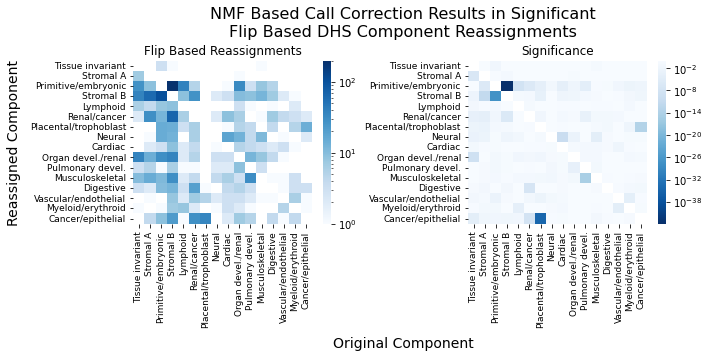

In [33]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 3))
# fig.tight_layout()
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.5, hspace=0)
fig.patch.set_facecolor('white')

comps_for_heatmap_no_spaces = ['Tissue invariant','Stromal A', 'Primitive/embryonic', 'Stromal B', 'Lymphoid', 'Renal/cancer', 'Placental/trophoblast', 'Neural', 'Cardiac', 'Organ devel./renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular/endothelial', 'Myeloid/erythroid', 'Cancer/epithelial']


axes = axes.ravel()
sns.heatmap(heatmap_mixture_all_cycles_top_comp_comparison_flipbased_sum, ax=axes[0], xticklabels=comps_for_heatmap_no_spaces, yticklabels=comps_for_heatmap_no_spaces, cmap='Blues', cbar=True, norm=LogNorm(vmax=200)) # 
axes[0].set_xticklabels(comps_for_heatmap_no_spaces, fontsize=9)
axes[0].set_yticklabels(comps_for_heatmap_no_spaces, fontsize=9)


sns.heatmap(heatmap_mixture_all_cycles_top_comp_flipbased_pvals, ax=axes[1], xticklabels=comps_for_heatmap_no_spaces, yticklabels=comps_for_heatmap_no_spaces, cmap='Blues_r', cbar=True, norm=LogNorm()) # 
axes[1].set_xticklabels(comps_for_heatmap_no_spaces, fontsize=9)
axes[1].set_yticklabels(comps_for_heatmap_no_spaces, fontsize=9)

axes[0].set_title('Flip Based Reassignments')
axes[1].set_title('Significance')



fig.text(-0.05, 0.5, 'Reassigned Component', va='center', rotation='vertical', fontsize=14)
fig.text(0.5, -0.45, 'Original Component', ha='center', fontsize=14)
plt.suptitle('NMF Based Call Correction Results in Significant\nFlip Based DHS Component Reassignments', fontsize=16, x=0.5, y=1.13)

In [72]:
dhss_3_to_2 = changed_dhss_all_cycles_flipbased[0][((changed_dhss_original_comp_flipbased[0]==3) & 
                                                    (changed_dhss_new_comp_flipbased[0]==2))]
numflips_3_to_2 = changed_dhss_numflips_flipbased[0][((changed_dhss_original_comp_flipbased[0]==3) & 
                                                      (changed_dhss_new_comp_flipbased[0]==2))]

dhss_2_to_3 = changed_dhss_all_cycles_flipbased[0][((changed_dhss_original_comp_flipbased[0]==2) & 
                                                    (changed_dhss_new_comp_flipbased[0]==3))]
numflips_2_to_3 = changed_dhss_numflips_flipbased[0][((changed_dhss_original_comp_flipbased[0]==2) & 
                                                      (changed_dhss_new_comp_flipbased[0]==3))]

dhss_6_to_15 = changed_dhss_all_cycles_flipbased[0][((changed_dhss_original_comp_flipbased[0]==6) & 
                                                     (changed_dhss_new_comp_flipbased[0]==15))]
numflips_6_to_15 = changed_dhss_numflips_flipbased[0][((changed_dhss_original_comp_flipbased[0]==6) & 
                                                       (changed_dhss_new_comp_flipbased[0]==15))]

In [85]:
numflips_3_to_2_sorted = numflips_3_to_2[np.argsort(-numflips_3_to_2)]
dhss_3_to_2_sorted = dhss_3_to_2[np.argsort(-numflips_3_to_2)]

numflips_2_to_3_sorted = numflips_2_to_3[np.argsort(-numflips_2_to_3)]
dhss_2_to_3_sorted = dhss_2_to_3[np.argsort(-numflips_2_to_3)]

numflips_6_to_15_sorted = numflips_6_to_15[np.argsort(-numflips_6_to_15)]
dhss_6_to_15_sorted = dhss_6_to_15[np.argsort(-numflips_6_to_15)]

In [87]:
dhss_3_to_2_sorted_chrm = np.array(DHS_metadata.loc[dhss_3_to_2_sorted]['seqname'])
dhss_3_to_2_sorted_start = np.array(DHS_metadata.loc[dhss_3_to_2_sorted]['start'])
dhss_3_to_2_sorted_end = np.array(DHS_metadata.loc[dhss_3_to_2_sorted]['end'])

dhss_2_to_3_sorted_chrm = np.array(DHS_metadata.loc[dhss_2_to_3_sorted]['seqname'])
dhss_2_to_3_sorted_start = np.array(DHS_metadata.loc[dhss_2_to_3_sorted]['start'])
dhss_2_to_3_sorted_end = np.array(DHS_metadata.loc[dhss_2_to_3_sorted]['end'])

dhss_6_to_15_sorted_chrm = np.array(DHS_metadata.loc[dhss_6_to_15_sorted]['seqname'])
dhss_6_to_15_sorted_start = np.array(DHS_metadata.loc[dhss_6_to_15_sorted]['start'])
dhss_6_to_15_sorted_end = np.array(DHS_metadata.loc[dhss_6_to_15_sorted]['end'])

In [88]:
# 3 to 2
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_threshold_flip_01thresh_reassigned_DHSs_3_to_2_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(dhss_3_to_2_sorted_chrm[i] + '\t' + str(dhss_3_to_2_sorted_start[i]) + '\t' + str(dhss_3_to_2_sorted_end[i]) + '\t' + str(numflips_3_to_2_sorted[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_threshold_flip_01thresh_reassigned_DHSs_3_to_2_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_threshold_flip_01thresh_reassigned_DHSs_3_to_2_by_numflips_CT20220408.bed


In [89]:
# 2 to 3
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_threshold_flip_01thresh_reassigned_DHSs_2_to_3_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(100):
    f.write(dhss_2_to_3_sorted_chrm[i] + '\t' + str(dhss_2_to_3_sorted_start[i]) + '\t' + str(dhss_2_to_3_sorted_end[i]) + '\t' + str(numflips_2_to_3_sorted[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_threshold_flip_01thresh_reassigned_DHSs_2_to_3_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_threshold_flip_01thresh_reassigned_DHSs_2_to_3_by_numflips_CT20220408.bed


In [93]:
# 6 to 15
today = date.today()
bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_threshold_flip_01thresh_reassigned_DHSs_6_to_15_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed')
f= open(bed_path_name, 'w')
for i in range(35):
    f.write(dhss_6_to_15_sorted_chrm[i] + '\t' + str(dhss_6_to_15_sorted_start[i]) + '\t' + str(dhss_6_to_15_sorted_end[i]) + '\t' + str(numflips_6_to_15_sorted[i]) + '\n')
f.close()
link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_threshold_flip_01thresh_reassigned_DHSs_6_to_15_by_numflips_CT' + today.strftime("%Y%m%d") + '.bed'
print(link_path)

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_threshold_flip_01thresh_reassigned_DHSs_6_to_15_by_numflips_CT20220408.bed


**5/19/22 Mixture and Basis Analysis**

In [12]:
mixture_all_cycles_top_comp = np.argmax(mixture_all_cycles, axis=1)
mixture_all_cycles_top_comp_val = np.max(mixture_all_cycles, axis=1)

basis_all_cycles_top_comp = np.argmax(basis_all_cycles, axis=2)
basis_all_cycles_top_comp_val = np.max(basis_all_cycles, axis=2)

In [27]:
removed_DHS_inds = removed_flat_inds_all_cycles[0]%n_DHSs
added_DHS_inds = added_flat_inds_all_cycles[0]%n_DHSs

removed_biosample_inds = removed_flat_inds_all_cycles[0]//n_DHSs
added_biosample_inds = added_flat_inds_all_cycles[0]//n_DHSs

In [28]:
flipped_DHS_inds = np.append(added_DHS_inds, removed_DHS_inds)
flipped_biosample_inds = np.append(added_biosample_inds, removed_biosample_inds)

In [18]:
np.bincount(np.bincount(flipped_DHS_inds))

array([3533371,   48825,    7197,    1348,     312,     106,      28,
             6,       4,       1])

In [12]:
np.bincount(np.bincount(flipped_DHS_inds)[np.bincount(flipped_DHS_inds)!=0])

array([    0, 48825,  7197,  1348,   312,   106,    28,     6,     4,
           1])

In [18]:
def histogram_wrapper(data):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    data_min = np.min(data)
    data_max = np.max(data)
#     data_counts = np.zeros(data_max-data_min+1)
#     for i in range(data_min, data_max+1):
#         data_counts[i-data_min] = len(data[data==i])
    data_counts = np.bincount(data)

    plt.fill_between(np.arange(data_min, data_max+1), data_counts, step='pre', alpha=1)
    plt.plot(np.arange(data_min, data_max+1), data_counts, drawstyle="steps")
    
    return fig

Text(0.5, 1.0, 'Calls Removed for Each Biosample')

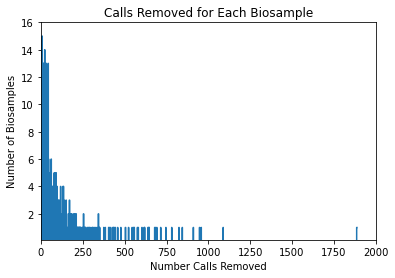

In [14]:
fig = histogram_wrapper(np.bincount(flipped_biosample_inds))
plt.xlim([0, 2000])
plt.ylim([0.1, 16])
plt.ylabel('Number of Biosamples')
plt.xlabel('Number Calls Removed')
plt.title('Calls Removed for Each Biosample')

In [15]:
describe(np.bincount(flipped_biosample_inds))

DescribeResult(nobs=733, minmax=(0, 1887), mean=94.53206002728513, variance=25280.530733045576, skewness=4.449513028801296, kurtosis=30.02908544929295)

In [16]:
mode(np.bincount(flipped_biosample_inds))

ModeResult(mode=array([7]), count=array([15]))

In [17]:
np.argsort(-np.bincount(flipped_biosample_inds))[:10]

array([ 44, 715, 102, 480, 601, 319, 600, 602, 643, 651])

In [18]:
biosample_df.loc[np.argsort(-np.bincount(flipped_biosample_inds))[:10]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
44,45,hESCT0,Primitive / embryonic,ENCSR000EMZ,ENCLB449ZZZ,ENCBS293AAA,AG4188,LN2365,DS11909,DS13133,...,minElute,80.0,14,NaN,NaN,2009-08-19,240791918,0.6453,315568,314868
715,716,DE,Primitive / embryonic,ENCSR166KPV,ENCLB393NTX,ENCBS088TSK,AG6944,LN43606A,DS55923A,DS39603C,...,NaN,NaN,1.1,540000.0,NaN,2017-01-05,457497776,0.5445,312848,307202
102,103,NHLF,Stromal B,ENCSR000EPR,ENCLB569ZZZ,ENCBS340AAA,AG4141,LN2632,DS12829,DS12834,...,minElute,120.0,8.8,NaN,NaN,2009-11-02,288918603,0.7161,293067,292691
480,481,Small_Intestine_Mucosa,Digestive,ENCSR931UQB,ENCLB776CXK,ENCBS853LFM,AG8858,LN4899,DS20770,NaN,...,minElute,60.0,63.7,6750000.0,A+Sucrose,2011-10-21,261183925,0.4702,187693,187198
601,602,fTongue,Musculoskeletal,ENCSR759UNY,ENCLB323PCN,ENCBS321GUH,AG3923,LN21290A,DS24808A,NaN,...,Sucrose,70.0,3.1,2790000.0,A+Sucrose,2013-10-24,368107814,0.4150,233230,232547
319,320,fMuscle_back,Musculoskeletal,ENCSR317SIH,ENCLB752ROB,ENCBS384LIR,AG9007,LN4072,DS17767,NaN,...,minElute,80.0,24,3600000.0,A+Sucrose,2011-01-13,348976677,0.5563,227382,225627
600,601,fSpinal_cord,Neural,ENCSR910OQF,ENCLB216GJK,ENCBS665NIQ,AG3922,LN21289A,DS24833A,NaN,...,Sucrose,60.0,1.8,4500000.0,A+Sucrose,2013-10-24,654629469,0.4399,298953,297421
602,603,fTongue,Musculoskeletal,ENCSR559WMK,ENCLB329UJC,ENCBS377XXD,AG3912,LN21292A,DS24888A,NaN,...,Sucrose,80.0,2.6,2610000.0,A+Sucrose,2013-11-05,359729577,0.4597,227994,227286
643,644,fHeart,Cardiac,ENCSR664PKM,ENCLB434QXK,ENCBS910QFW,AG3958,LN26948A,DS24812A,NaN,...,Sucrose,NaN,5.89,560000.0,A+Sucrose,2013-10-15,492718541,0.3958,200817,199314
651,652,Trophoblast,Placental / trophoblast,ENCSR121ZSL,ENCLB873PCM,ENCBS627LRI,AG3818,LN28076A,DS30587A,DS35778S,...,NaN,NaN,4,720000.0,PBS+A,2014-08-19,666187813,0.5675,355914,354918


*Top comp comparison*

In [20]:
mixture_all_cycles_top_comp_val_diff = mixture_all_cycles_top_comp_val[0] - mixture_all_cycles_top_comp_val[1]
basis_all_cycles_top_comp_val_diff = basis_all_cycles_top_comp_val[0] - basis_all_cycles_top_comp_val[1]

In [365]:
np.max(basis_all_cycles_top_comp_val_diff)

0.039889336

In [350]:
describe(mixture_all_cycles_top_comp_val_diff)

DescribeResult(nobs=3591898, minmax=(-0.044619948, 0.0136362165), mean=1.4527199e-06, variance=5.5631807e-07, skewness=-17.602090751866253, kurtosis=423.0188087973309)

Text(0.5, 1.0, 'DHS NMF Mixture Component Margin')

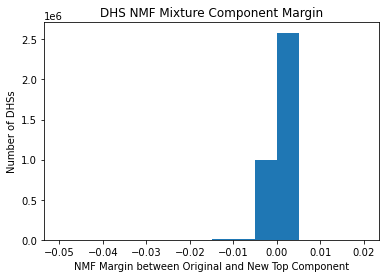

In [366]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(mixture_all_cycles_top_comp_val_diff, 
        bins=np.arange(-0.05, 0.02, 0.005))

# plt.yscale('log')
plt.xlabel('NMF Margin between Original and New Top Component')
plt.ylabel('Number of DHSs')
plt.title('DHS NMF Mixture Component Margin')

Text(0.5, 1.0, 'DHS NMF Mixture Component Margin')

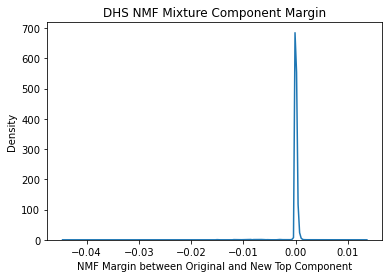

In [367]:
fig = plt.figure()
fig.patch.set_facecolor('white')

sns.kdeplot(mixture_all_cycles_top_comp_val_diff, bw_adjust=0.1)

plt.xlabel('NMF Margin between Original and New Top Component')
plt.ylabel('Density')
plt.title('DHS NMF Mixture Component Margin')

Text(0.5, 1.0, 'Biosample NMF Basis Component Margin')

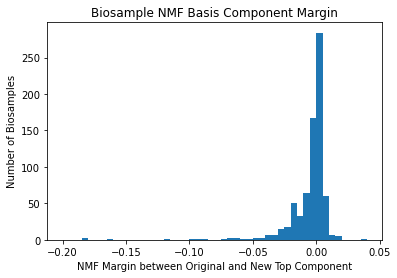

In [370]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(basis_all_cycles_top_comp_val_diff, 
        bins=np.arange(-0.2, 0.045, 0.005))

# plt.yscale('log')
plt.xlabel('NMF Margin between Original and New Top Component')
plt.ylabel('Number of Biosamples')
plt.title('Biosample NMF Basis Component Margin')

Text(0.5, 1.0, 'Biosample NMF Basis Component Margin')

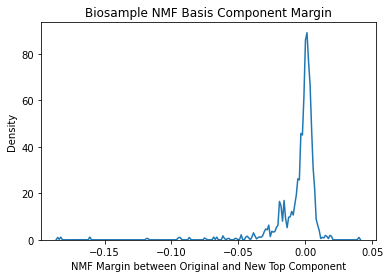

In [368]:
fig = plt.figure()
fig.patch.set_facecolor('white')

sns.kdeplot(basis_all_cycles_top_comp_val_diff, bw_adjust=0.1)

plt.xlabel('NMF Margin between Original and New Top Component')
plt.ylabel('Density')
plt.title('Biosample NMF Basis Component Margin')

*Winning Comp Margin*

In [21]:
# normalizing mixture arrays
norm_mixture_cycle0 = mixture_all_cycles[0, :, :]/np.sum(mixture_all_cycles[0], axis=0)
norm_mixture_cycle1 = mixture_all_cycles[1, :, :]/np.sum(mixture_all_cycles[1], axis=0)
mixture_all_cycles_norm = np.array([norm_mixture_cycle0, norm_mixture_cycle1])
mixture_all_cycles_norm.shape

(2, 16, 3591898)

In [22]:
#finding the first and second top component top component val for each DHS
mixture_all_cycles_norm_top_comp = np.argmax(mixture_all_cycles_norm, axis=1)
mixture_all_cycles_norm_top_comp_val = np.max(mixture_all_cycles_norm, axis=1)

mixture_all_cycles_norm_2_top_comp = np.argsort(-mixture_all_cycles_norm, axis=1)[:, 1, :]
mixture_all_cycles_norm_2_top_comp_val = -np.sort(-mixture_all_cycles_norm, axis=1)[:, 1, :]

In [23]:
#margin
mixture_all_cycles_norm_top_comp_val_diff = mixture_all_cycles_norm_top_comp_val - mixture_all_cycles_norm_2_top_comp_val

Text(0.5, 1.0, 'Normalized DHS NMF Mixture Component Margin')

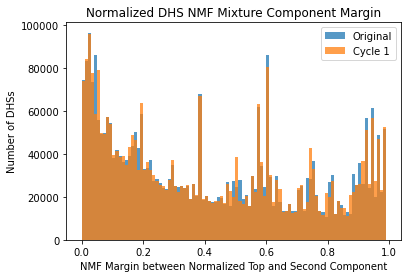

In [203]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(mixture_all_cycles_norm_top_comp_val_diff[0, :], 
        bins=np.arange(0, 1, 0.01), 
        alpha=0.75)
plt.hist(mixture_all_cycles_norm_top_comp_val_diff[1, :], 
        bins=np.arange(0, 1, 0.01), 
        alpha=0.75)

plt.xlabel('NMF Margin between Normalized Top and Second Component')
plt.ylabel('Number of DHSs')
plt.legend(['Original', 'Cycle 1'])
plt.title('Normalized DHS NMF Mixture Component Margin')

Text(0.5, 1.0, 'Normalized DHS NMF Mixture Component Margin')

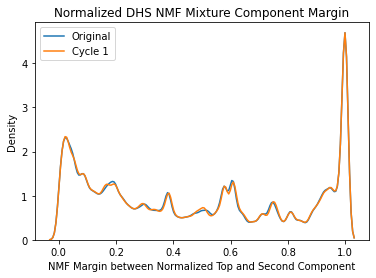

In [378]:
fig = plt.figure()
fig.patch.set_facecolor('white')

sns.kdeplot(mixture_all_cycles_norm_top_comp_val_diff[0, :], bw_adjust=0.6)
sns.kdeplot(mixture_all_cycles_norm_top_comp_val_diff[1, :], bw_adjust=0.6)

plt.xlabel('NMF Margin between Normalized Top and Second Component')
plt.ylabel('Density')
plt.legend(['Original', 'Cycle 1'])
plt.title('Normalized DHS NMF Mixture Component Margin')

In [25]:
# normalizing basis arrays
norm_basis_cycle0 = (basis_all_cycles[0, :, :].T/np.sum(basis_all_cycles[0], axis=1)).T
norm_basis_cycle1 = (basis_all_cycles[1, :, :].T/np.sum(basis_all_cycles[1], axis=1)).T
basis_all_cycles_norm = np.array([norm_basis_cycle0, norm_basis_cycle1])

In [28]:
basis_all_cycles_norm_top_comp = np.argmax(basis_all_cycles_norm, axis=2)

In [26]:
#finding the first and second top component top component val for each DHS
basis_all_cycles_norm_top_comp = np.argmax(basis_all_cycles_norm, axis=2)
basis_all_cycles_norm_top_comp_val = np.max(basis_all_cycles_norm, axis=2)

basis_all_cycles_norm_2_top_comp = np.argsort(-basis_all_cycles_norm, axis=2)[:, :, 1]
basis_all_cycles_norm_2_top_comp_val = -np.sort(-basis_all_cycles_norm, axis=2)[:, :, 1]

In [27]:
#margin
basis_all_cycles_norm_top_comp_val_diff = basis_all_cycles_norm_top_comp_val - basis_all_cycles_norm_2_top_comp_val

Text(0.5, 1.0, 'Normalized Biosample NMF Basis Component Margin')

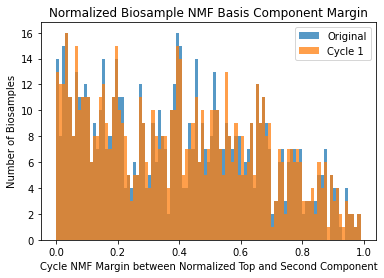

In [264]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(basis_all_cycles_norm_top_comp_val_diff[0, :], 
        bins=np.arange(0, 1, 0.01), 
        alpha=0.75)
plt.hist(basis_all_cycles_norm_top_comp_val_diff[1, :], 
        bins=np.arange(0, 1, 0.01), 
        alpha=0.75)

plt.xlabel('Cycle NMF Margin between Normalized Top and Second Component')
plt.ylabel('Number of Biosamples')
plt.legend(['Original', 'Cycle 1'])
plt.title('Normalized Biosample NMF Basis Component Margin')

Text(0.5, 1.0, 'Normalized Biosample NMF Basis Component Margin')

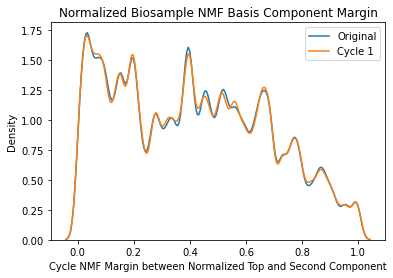

In [359]:
fig = plt.figure()
fig.patch.set_facecolor('white')

sns.kdeplot(basis_all_cycles_norm_top_comp_val_diff[0, :], bw_adjust=0.2)
sns.kdeplot(basis_all_cycles_norm_top_comp_val_diff[1, :], bw_adjust=0.2)

plt.xlabel('Cycle NMF Margin between Normalized Top and Second Component')
plt.ylabel('Density')
plt.legend(['Original', 'Cycle 1'])
plt.title('Normalized Biosample NMF Basis Component Margin')

*number of flipped DHSs per biosample*

In [246]:
np.bincount(flipped_biosample_inds)[[411, 486, 531, 719, 728]]

array([ 25,  29,  63, 430,   6])

Text(0.5, 1.0, 'Calls Flipped in Each Biosample')

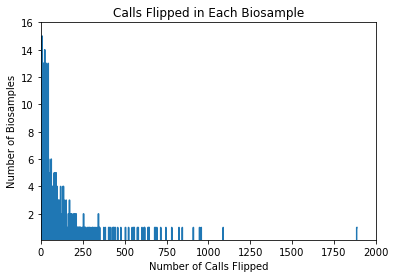

In [32]:
fig = histogram_wrapper(np.bincount(flipped_biosample_inds))

plt.xlim([0, 2000])
plt.ylim([0.1, 16])
plt.ylabel('Number of Biosamples')
plt.xlabel('Number of Calls Flipped')
plt.title('Calls Flipped in Each Biosample')

Text(0.5, 1.0, 'Calls Flipped in Each Biosample')

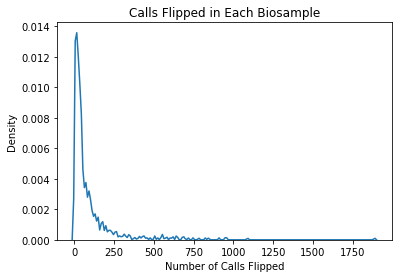

In [31]:
fig = plt.figure()
fig.patch.set_facecolor('white')


sns.kdeplot(np.bincount(flipped_biosample_inds), bw_adjust=0.1)
# plt.xlim([0, 2000])
# plt.ylim([0.1, 16])
plt.ylabel('Density')
plt.xlabel('Number of Calls Flipped')
plt.title('Calls Flipped in Each Biosample')

*Flip Based and non-flip based DHS number of 0 comps*

In [315]:
mixture_all_cycles_flipbased = mixture_all_cycles[:, :, changed_dhss_all_cycles_flipbased[0]]
mixture_all_cycles_notflipbased = mixture_all_cycles[:, :, changed_dhss_all_cycles_notflipbased[0]]

mixture_all_cycles_flipbased_zeros = 16-np.count_nonzero(mixture_all_cycles_flipbased, axis=1)
mixture_all_cycles_notflipbased_zeros = 16-np.count_nonzero(mixture_all_cycles_notflipbased, axis=1)

Text(0.5, 1.0, '0 Values in DHS NMF Mixture Loadings')

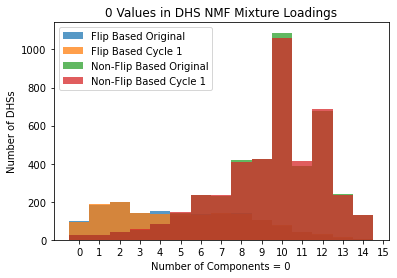

In [328]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.hist(mixture_all_cycles_flipbased_zeros[0, :], 
        bins=np.arange(0, 16, 1), 
        alpha=0.75,
        align='left')
plt.hist(mixture_all_cycles_flipbased_zeros[1, :], 
        bins=np.arange(0, 16, 1), 
        alpha=0.75,
        align='left')
plt.hist(mixture_all_cycles_notflipbased_zeros[0, :], 
        bins=np.arange(0, 16, 1), 
        alpha=0.75,
        align='left')
plt.hist(mixture_all_cycles_notflipbased_zeros[1, :], 
        bins=np.arange(0, 16, 1), 
        alpha=0.75,
        align='left')

plt.xticks(np.arange(0, 16, 1), np.arange(0, 16, 1))

plt.xlabel('Number of Components = 0')
plt.ylabel('Number of DHSs')
plt.legend(['Flip Based Original', 'Flip Based Cycle 1', 'Non-Flip Based Original', 'Non-Flip Based Cycle 1'])
plt.title('0 Values in DHS NMF Mixture Loadings')

Text(0.5, 1.0, 'Number of 0 Values in DHS NMF Mixture Loadings')

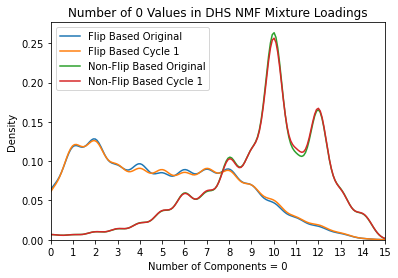

In [341]:
fig = plt.figure()
fig.patch.set_facecolor('white')

sns.kdeplot(mixture_all_cycles_flipbased_zeros[0, :], bw_adjust=0.6)
sns.kdeplot(mixture_all_cycles_flipbased_zeros[1, :], bw_adjust=0.6)
sns.kdeplot(mixture_all_cycles_notflipbased_zeros[0, :], bw_adjust=0.8)
sns.kdeplot(mixture_all_cycles_notflipbased_zeros[1, :], bw_adjust=0.8)

plt.xticks(np.arange(0, 16, 1), np.arange(0, 16, 1))

plt.xlabel('Number of Components = 0')
plt.xlim([0, 15])
plt.ylabel('Density')
plt.legend(['Flip Based Original', 'Flip Based Cycle 1', 'Non-Flip Based Original', 'Non-Flip Based Cycle 1'])
plt.title('Number of 0 Values in DHS NMF Mixture Loadings')

*extra from 5/18/22*

Text(0.5, 1.0, 'Biosamples with More Flips Experience\nGreater Change in NMF Loadings')

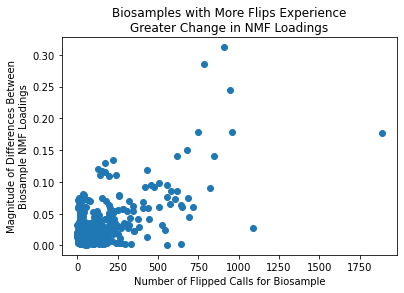

In [377]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(np.bincount(flipped_biosample_inds), 
            np.sum(np.abs(basis_all_cycles[0]-basis_all_cycles[1]), axis=1))

plt.ylabel('Magnitude of Differences Between\nBiosample NMF Loadings')
plt.xlabel('Number of Flipped Calls for Biosample')
plt.title('Biosamples with More Flips Experience\nGreater Change in NMF Loadings')

**5/23/22 Extreme Biosample NMF Analysis**

In [13]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    return fig

*Seeing if NMF embeddings are larger for biosamples with most flipped calls*

In [14]:
np.argsort(-np.bincount(added_biosample_inds))[:3]

array([ 44, 102, 480])

In [15]:
basis_all_cycles_compsummed = np.sum(basis_all_cycles, axis=2)
print(basis_all_cycles_compsummed[0, [44, 715, 102]])
print(basis_all_cycles_compsummed[0, [44, 102, 480, 333]])

[8.036437  6.6218786 9.754776 ]
[ 8.036437  9.754776 12.99345  16.459444]


In [16]:
np.argmax(basis_all_cycles_compsummed[0])
np.where(np.argsort(-np.bincount(added_biosample_inds))==333)
-np.sort(-np.bincount(added_biosample_inds))[94]

138

Text(0.5, 1.0, 'Sum of NMF Basis Components with Number of Added Calls')

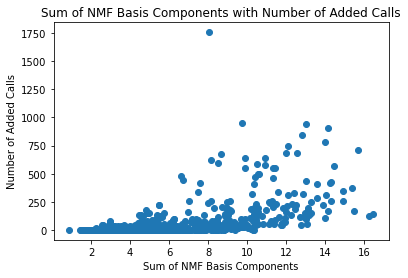

In [17]:
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.scatter(basis_all_cycles_compsummed[0], np.append(np.bincount(added_biosample_inds), [0, 0, 0]))
plt.xlabel('Sum of NMF Basis Components')
plt.ylabel('Number of Added Calls')
plt.title('Sum of NMF Basis Components with Number of Added Calls')

DescribeResult(nobs=733, minmax=(0.85877985, 16.459444), mean=6.148122, variance=9.6135025, skewness=0.8756720622433957, kurtosis=0.17371027564499553)


Text(0.5, 1.0, 'Sum of NMF Basis Components for Each Biosample')

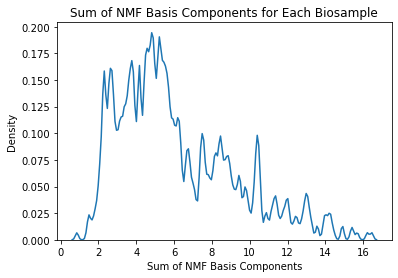

In [18]:
fig = kde_wrapper(basis_all_cycles_compsummed[0], bw=0.1)
plt.xlabel('Sum of NMF Basis Components')
plt.ylabel('Density')
plt.title('Sum of NMF Basis Components for Each Biosample')

In [19]:
basis_all_cycles_compmax = np.max(basis_all_cycles, axis=2)
print(basis_all_cycles_compmax[0, [44, 715, 102]])
print(basis_all_cycles_compmax[0, [44, 102, 480, 651]])

[6.8047767 6.6135263 4.4848385]
[ 6.8047767  4.4848385  8.575191  14.680075 ]


In [20]:
np.argmax(basis_all_cycles_compmax[0])
np.where(np.argsort(-np.bincount(added_biosample_inds))==651)
-np.sort(-np.bincount(added_biosample_inds))[7]

714

Text(0.5, 1.0, 'Max of NMF Basis Components with Number of Added Calls')

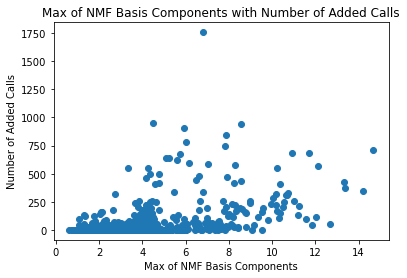

In [21]:
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.scatter(basis_all_cycles_compmax[0], np.append(np.bincount(added_biosample_inds), [0, 0, 0]))
plt.xlabel('Max of NMF Basis Components')
plt.ylabel('Number of Added Calls')
plt.title('Max of NMF Basis Components with Number of Added Calls')

DescribeResult(nobs=733, minmax=(0.6066141, 14.680075), mean=3.8438935, variance=5.972882, skewness=1.4436517805400726, kurtosis=2.202747824771209)


Text(0.5, 1.0, 'Max of NMF Basis Components for Each Biosample')

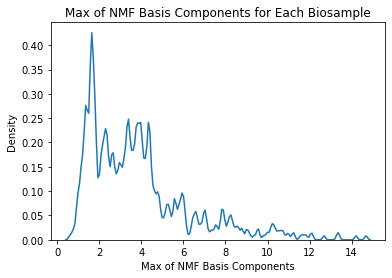

In [22]:
fig = kde_wrapper(basis_all_cycles_compmax[0], bw=0.1)
plt.xlabel('Max of NMF Basis Components')
plt.ylabel('Density')
plt.title('Max of NMF Basis Components for Each Biosample')

In [23]:
original_numdhss_per_biosample = np.array(biosample_df['DHSs in Index'])
basis_all_cycles_compsummed_over_numdhss = basis_all_cycles_compsummed[0]/original_numdhss_per_biosample
print(basis_all_cycles_compsummed_over_numdhss[[44, 715, 102]])
print(basis_all_cycles_compsummed_over_numdhss[[44, 102, 480]])

[2.55231940e-05 2.15554541e-05 3.33278987e-05]
[2.55231940e-05 3.33278987e-05 6.94101976e-05]


Text(0.5, 1.0, 'Sum of NMF Basis Components/Number of DHSs with Number of Added Calls')

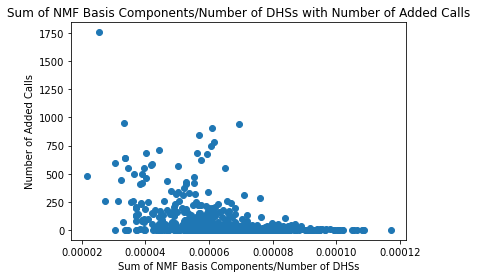

In [24]:
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.scatter(basis_all_cycles_compsummed_over_numdhss, np.append(np.bincount(added_biosample_inds), [0, 0, 0]))
plt.xlabel('Sum of NMF Basis Components/Number of DHSs')
plt.ylabel('Number of Added Calls')
plt.title('Sum of NMF Basis Components/Number of DHSs with Number of Added Calls')

In [25]:
original_numdhss_per_biosample = np.array(biosample_df['DHSs in Index'])
basis_all_cycles_compmax_over_numdhss = basis_all_cycles_compmax[0]/original_numdhss_per_biosample
print(basis_all_cycles_compmax_over_numdhss[[44, 715, 102]])
print(basis_all_cycles_compmax_over_numdhss[[44, 102, 480, 265, 471]])

[2.16115219e-05 2.15282659e-05 1.53227755e-05]
[2.16115219e-05 1.53227755e-05 4.58081312e-05 1.04022419e-04
 8.44360216e-06]


In [26]:
np.argmax(basis_all_cycles_compmax_over_numdhss)
np.where(np.argsort(-np.bincount(added_biosample_inds))==265)
-np.sort(-np.bincount(added_biosample_inds))[700]

0

Text(0.5, 1.0, 'Original Number of DHSs with Number of Added Calls')

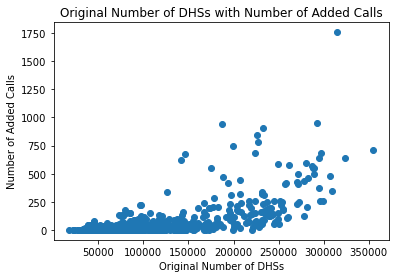

In [27]:
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.scatter(original_numdhss_per_biosample, np.append(np.bincount(added_biosample_inds), [0, 0, 0]))
plt.xlabel('Original Number of DHSs')
plt.ylabel('Number of Added Calls')
plt.title('Original Number of DHSs with Number of Added Calls')

Text(0.5, 1.0, 'Original Number of DHSs with Number of Removed Calls')

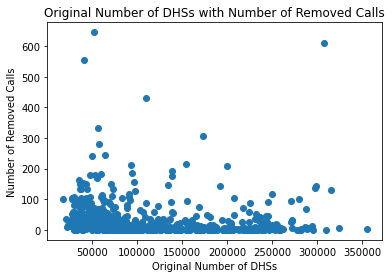

In [28]:
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.scatter(original_numdhss_per_biosample, np.bincount(removed_biosample_inds))
plt.xlabel('Original Number of DHSs')
plt.ylabel('Number of Removed Calls')
plt.title('Original Number of DHSs with Number of Removed Calls')

Text(0.5, 1.0, 'NMF Basis Top Component Value/Number of DHSs with Number of Added Calls')

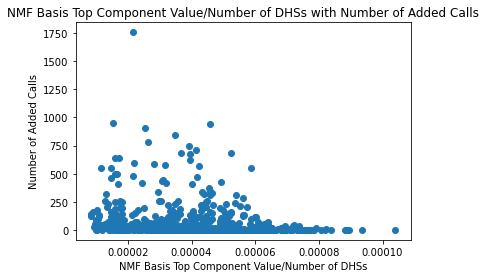

In [29]:
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.scatter(basis_all_cycles_compmax_over_numdhss, np.append(np.bincount(added_biosample_inds), [0, 0, 0]))
plt.xlabel('NMF Basis Top Component Value/Number of DHSs')
plt.ylabel('Number of Added Calls')
plt.title('NMF Basis Top Component Value/Number of DHSs with Number of Added Calls')

DescribeResult(nobs=733, minmax=(8.443602159547824e-06, 0.00010402241896719429), mean=4.163890874776021e-05, variance=2.791890322773296e-10, skewness=0.21664314432769488, kurtosis=-0.1676010048098009)


Text(0.5, 1.0, 'NMF Basis Top Component Value/Number of DHSs')

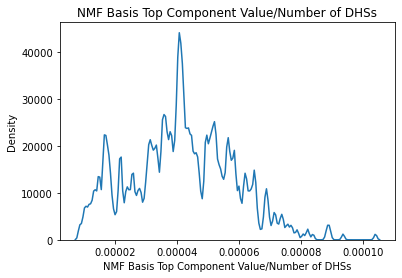

In [30]:
fig = kde_wrapper(basis_all_cycles_compmax_over_numdhss, bw=0.1)
plt.xlabel('NMF Basis Top Component Value/Number of DHSs')
plt.ylabel('Density')
plt.title('NMF Basis Top Component Value/Number of DHSs')

*Perhaps does this have someything to do with the biosamples "presence" in biosamples of similar component*

In [31]:
#for each biosample, finding the percent of presence in DHSs of each component
biosample_percent_filled_by_comp = np.zeros((733, 16))
for comp in range(16):
    dhss_per_comp = np.where(mixture_all_cycles_top_comp[0, :]==comp)[0]
    counts_per_comp = np.sum(cycle0_dhs_arr[:, dhss_per_comp], axis=1)
    biosample_percent_filled_by_comp[:, comp] = counts_per_comp / len(dhss_per_comp)

In [32]:
biosample_top_comp_fill_percentage = []
for biosample in range(733):
    top_comp = basis_all_cycles_top_comp[0, biosample]
    biosample_top_comp_fill_percentage.append(biosample_percent_filled_by_comp[biosample, top_comp])
biosample_top_comp_fill_percentage = np.array(biosample_top_comp_fill_percentage)
print(biosample_top_comp_fill_percentage[[44, 715, 102]])
print(biosample_top_comp_fill_percentage[[44, 102, 480, 160]])

[0.27330055 0.33334131 0.33228118]
[0.27330055 0.33228118 0.37656638 0.00600035]


In [33]:
np.argmin(biosample_top_comp_fill_percentage)
np.where(np.argsort(-np.bincount(added_biosample_inds))==160)
-np.sort(-np.bincount(added_biosample_inds))[234]

31

In [34]:
basis_all_cycles_top_comp[0, 102]

3

Text(0.5, 1.0, 'Top Component Fill Percentage with Number of Added Calls')

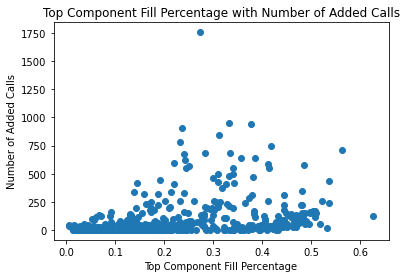

In [35]:
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.scatter(biosample_top_comp_fill_percentage, np.append(np.bincount(added_biosample_inds), [0, 0, 0]))
plt.xlabel('Top Component Fill Percentage')
plt.ylabel('Number of Added Calls')
plt.title('Top Component Fill Percentage with Number of Added Calls')

DescribeResult(nobs=733, minmax=(0.00600035015305933, 0.6266641762392471), mean=0.18043856478556355, variance=0.01840583337764217, skewness=0.9514007769097569, kurtosis=-0.09850281215375478)


Text(0.5, 1.0, 'Top Component Fill Percentage')

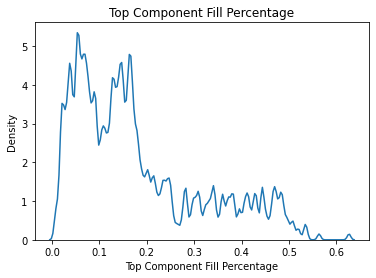

In [36]:
#subsetting by biosamples of each component
fig = kde_wrapper(biosample_top_comp_fill_percentage, bw=0.1)#[np.where(basis_all_cycles_top_comp[0]==3)[0]]
plt.xlabel('Top Component Fill Percentage')
plt.ylabel('Density')
plt.title('Top Component Fill Percentage')

Text(0.5, 0.94, 'Comparing Metrics for Explaining Number of Added Calls')

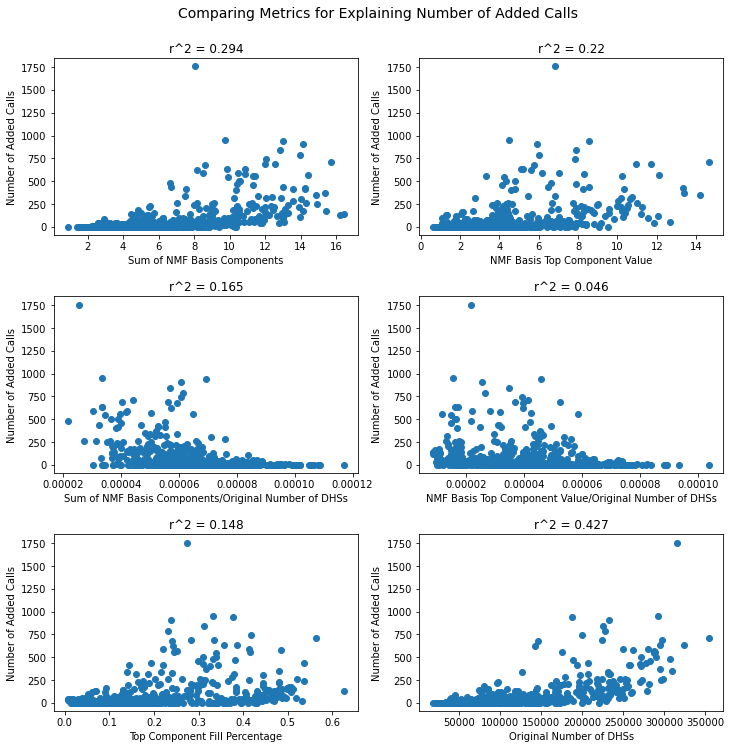

In [37]:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12,12))
fig.patch.set_facecolor('white')
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.2, hspace=0.35)

axes = axes.ravel()

x = basis_all_cycles_compsummed[0]
y = np.append(np.bincount(added_biosample_inds), [0, 0, 0])
axes[0].scatter(x, y)
axes[0].set_xlabel('Sum of NMF Basis Components')
axes[0].set_ylabel('Number of Added Calls')
axes[0].set_title('r^2 = ' + str(np.round(np.corrcoef(x, y)[0, 1]**2, 3)))

x = basis_all_cycles_compmax[0]
y = np.append(np.bincount(added_biosample_inds), [0, 0, 0])
axes[1].scatter(x, y)
axes[1].set_xlabel('NMF Basis Top Component Value')
axes[1].set_ylabel('Number of Added Calls')
axes[1].set_title('r^2 = ' + str(np.round(np.corrcoef(x, y)[0, 1]**2, 3)))
# axes[1].set_title('Max of NMF Basis Components\nwith Number of Added Calls')

x = basis_all_cycles_compsummed_over_numdhss
y = np.append(np.bincount(added_biosample_inds), [0, 0, 0])
axes[2].scatter(x, y)
axes[2].set_xlabel('Sum of NMF Basis Components/Original Number of DHSs')
axes[2].set_ylabel('Number of Added Calls')
axes[2].set_title('r^2 = ' + str(np.round(np.corrcoef(x, y)[0, 1]**2, 3)))
# axes[2].set_title('Sum of NMF Basis Components/Number of DHSs with Number of Added Calls')

x = basis_all_cycles_compmax_over_numdhss
y = np.append(np.bincount(added_biosample_inds), [0, 0, 0])
axes[3].scatter(x, y)
axes[3].set_xlabel('NMF Basis Top Component Value/Original Number of DHSs')
axes[3].set_ylabel('Number of Added Calls')
axes[3].set_title('r^2 = ' + str(np.round(np.corrcoef(x, y)[0, 1]**2, 3)))
# axes[3].set_title('NMF Basis Top Component Value/Number of DHSs\nwith Number of Added Calls')

x = biosample_top_comp_fill_percentage
y = np.append(np.bincount(added_biosample_inds), [0, 0, 0])
axes[4].scatter(x, y)
axes[4].set_xlabel('Top Component Fill Percentage')
axes[4].set_ylabel('Number of Added Calls')
axes[4].set_title('r^2 = ' + str(np.round(np.corrcoef(x, y)[0, 1]**2, 3)))
# axes[4].set_title('Top Component Fill Percentage\nwith Number of Added Calls')

x = original_numdhss_per_biosample
y = np.append(np.bincount(added_biosample_inds), [0, 0, 0])
axes[5].scatter(x, y)
axes[5].set_xlabel('Original Number of DHSs')
axes[5].set_ylabel('Number of Added Calls')
axes[5].set_title('r^2 = ' + str(np.round(np.corrcoef(x, y)[0, 1]**2, 3)))
# axes[5].set_title('Original Number of DHSs\nwith Number of Added Calls')

fig.suptitle('Comparing Metrics for Explaining Number of Added Calls', fontsize=14, y=0.94)

# x = original_numdhss_per_biosample
# y = np.bincount(removed_biosample_inds)
# axes[6].scatter(x, y)
# axes[6].set_xlabel('Original Number of DHSs')
# axes[6].set_ylabel('Number of Removed Calls')
# axes[6].set_title('r^2 = ' + str(np.round(np.corrcoef(x, y)[0, 1]**2, 3)))
# # axes[6].set_title('Original Number of DHSs\nwith Number of Removed Calls')

In [65]:
biosamples_all_cycles_num_zeros = 16-np.count_nonzero(basis_all_cycles, axis=2)

Text(0.5, 0.94, 'Comparing Metrics for Explaining Number of Removed Calls')

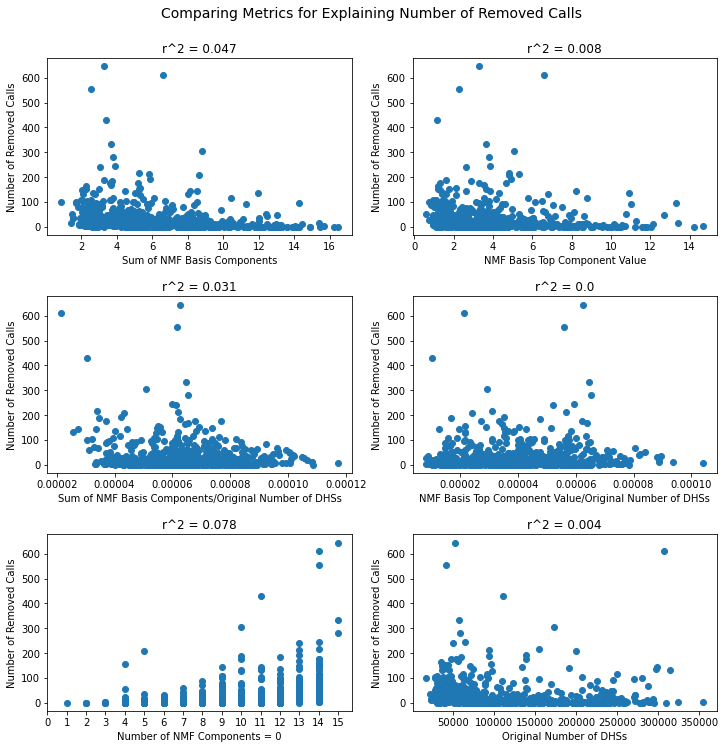

In [66]:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12,12))
fig.patch.set_facecolor('white')
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.2, hspace=0.35)

axes = axes.ravel()

x = basis_all_cycles_compsummed[0]
y = np.bincount(removed_biosample_inds)
axes[0].scatter(x, y)
axes[0].set_xlabel('Sum of NMF Basis Components')
axes[0].set_ylabel('Number of Removed Calls')
axes[0].set_title('r^2 = ' + str(np.round(np.corrcoef(x, y)[0, 1]**2, 3)))

x = basis_all_cycles_compmax[0]
y = np.bincount(removed_biosample_inds)
axes[1].scatter(x, y)
axes[1].set_xlabel('NMF Basis Top Component Value')
axes[1].set_ylabel('Number of Removed Calls')
axes[1].set_title('r^2 = ' + str(np.round(np.corrcoef(x, y)[0, 1]**2, 3)))
# axes[1].set_title('Max of NMF Basis Components\nwith Number of removed Calls')

x = basis_all_cycles_compsummed_over_numdhss
y = np.bincount(removed_biosample_inds)
axes[2].scatter(x, y)
axes[2].set_xlabel('Sum of NMF Basis Components/Original Number of DHSs')
axes[2].set_ylabel('Number of Removed Calls')
axes[2].set_title('r^2 = ' + str(np.round(np.corrcoef(x, y)[0, 1]**2, 3)))
# axes[2].set_title('Sum of NMF Basis Components/Number of DHSs with Number of removed Calls')

x = basis_all_cycles_compmax_over_numdhss
y = np.bincount(removed_biosample_inds)
axes[3].scatter(x, y)
axes[3].set_xlabel('NMF Basis Top Component Value/Original Number of DHSs')
axes[3].set_ylabel('Number of Removed Calls')
axes[3].set_title('r^2 = ' + str(np.round(np.corrcoef(x, y)[0, 1]**2, 3)))
# axes[3].set_title('NMF Basis Top Component Value/Number of DHSs\nwith Number of removed Calls')

x = biosamples_all_cycles_num_zeros[0]
y = np.bincount(removed_biosample_inds)
axes[4].scatter(x, y)
axes[4].set_xlabel('Number of NMF Components = 0')
axes[4].set_ylabel('Number of Removed Calls')
axes[4].set_xticks(np.arange(16))
axes[4].set_title('r^2 = ' + str(np.round(np.corrcoef(x, y)[0, 1]**2, 3)))

# x = biosample_top_comp_fill_percentage
# y = np.bincount(removed_biosample_inds)
# axes[4].scatter(x, y)
# axes[4].set_xlabel('Top Component Fill Percentage')
# axes[4].set_ylabel('Number of Removed Calls')
# axes[4].set_title('r^2 = ' + str(np.round(np.corrcoef(x, y)[0, 1]**2, 3)))
# # axes[4].set_title('Top Component Fill Percentage\nwith Number of removed Calls')

x = original_numdhss_per_biosample
y = np.bincount(removed_biosample_inds)
axes[5].scatter(x, y)
axes[5].set_xlabel('Original Number of DHSs')
axes[5].set_ylabel('Number of Removed Calls')
axes[5].set_title('r^2 = ' + str(np.round(np.corrcoef(x, y)[0, 1]**2, 3)))
# axes[5].set_title('Original Number of DHSs\nwith Number of removed Calls')

fig.suptitle('Comparing Metrics for Explaining Number of Removed Calls', fontsize=14, y=0.94)

# x = original_numdhss_per_biosample
# y = np.bincount(removed_biosample_inds)
# axes[6].scatter(x, y)
# axes[6].set_xlabel('Original Number of DHSs')
# axes[6].set_ylabel('Number of Removed Calls')
# axes[6].set_title('r^2 = ' + str(np.round(np.corrcoef(x, y)[0, 1]**2, 3)))
# # axes[6].set_title('Original Number of DHSs\nwith Number of Removed Calls')